### Innitialisation

In [2]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from functools import reduce
import seaborn as sns
from pyspark.sql import SparkSession
from itertools import combinations
import numpy as np
import pandas as pd


spark = (
    SparkSession.builder
    .getOrCreate()
)

### Nettoyage du fichier

In [3]:
df_raw = spark.read.option("multiLine", True).json("../data/personnages_fr.json")
#On retire les premier label qui entoure les personnages
df_perso = (
    df_raw.select(F.explode("personnages").alias("p")).select("p.*")
)


#On retire les label EN et JP et doublons et ce qui nous intéresse pas
df_perso = df_perso.drop("nom_en", "nom_jp", "stats_lvl_100", "description")

def clean_slot(slot):
    s = F.col(f"competences.{slot}")
    return s.withField(
        "niveaux",
        F.transform(s["niveaux"], lambda n: n.dropFields("nom_jp", "description_jp"))
    )

slots = ["competence_1", "competence_2", "competence_3", "incarnation"]

df_perso = df_perso.withColumn(
    "competences",
    F.struct(*[clean_slot(s).alias(s) for s in slots])
)

print("Nettoyage : \n- Des labes non concerné par des personnages\n- Des partie EN et JP \n- Des description des personnages ")

Nettoyage : 
- Des labes non concerné par des personnages
- Des partie EN et JP 
- Des description des personnages 


In [4]:
df_perso_complet = df_perso      # copie de référence, avec tous les persos


import unicodedata, re

# Persos free (nom, titre tel qu'écrit dans le JSON)
PERSOS_FREE = [
    ("Yuuki", "Sparkling Sunshine Girl"), ("Kirito", "Magical Stream"), ("Yui", "Petit cupidon"),
    ("Leafa", "Viser toujours plus haut"), ("Yui", "Le rêve d'une jeune épéiste"),
    ("Anna Mochizuki", "Let's enjoy the game"), ("Lisbeth", "L'heure de fêter le Nouvel An"),
    ("Kibaou", "Attends un peu !"), ("Suguha", "Panique dans la piscine"),
    ("Tizée", "Voulez-vous danser avec moi ?"), ("Klein", "La lumière de confiance"),
    ("Silica", "De tout mon cœur"), ("La responsable de l'ascenseur", "Tel le souffle du vent"),
    ("Soltirina", "Une technique sans égale"), ("Eugeo", "Rêve étoilé"),
    ("Tizée", "La Belle de la fête de la récolte"), ("Sachi", "Pour toi, mon cher"),
    ("Leafa", "Le temps des secrets entre filles"), ("Medina", "La Volonté au combat"),
    ("Silica", "Déjeuner au bord du lac"), ("Tizée", "Continuer ma route avec toi"),
    ("Eugeo", "Le petit aventurier"), ("Argo", "Les griffes scintillantes"),
    ("Kirito", "Le nouveau vent rapide"), ("Yui", "La jeune fille du matin brumeux"),
    ("Sinon", "Fée-chat de l'extase"), ("Soltirina", "Une cérémonie du thé splendide"),
    ("Kirito", "L'éveil du héros"), ("Bercouli", "La Lune, le saké, et toi"),
    ("Leafa", "Aurore au pays des fées"), ("Selka", "Le style qui me ressemble"),
    ("Alice", "Un souvenir d'enfance"), ("Alice", "Le Chevalier déterminé"),
    ("Soltirina", "Le style Serult d'une enfant"),
    ("Alice", "Un autre chemin"), ("Asuna", "Ardente étincelle"), ("Scheta", "Faire confiance"),
]

def _cle(texte):
    """Comparaison tolérante : apostrophes, espaces insécables, majuscules."""
    t = unicodedata.normalize("NFKC", texte or "").replace("’", "'")
    return re.sub(r"\s+", " ", t).strip().lower()

cles_free = {_cle(f"[{titre}] {nom}") for nom, titre in PERSOS_FREE}
ids_free = [r["id"] for r in df_perso_complet.select("id", "nom_complet").collect()
            if _cle(r["nom_complet"]) in cles_free]

# Contrôle : chaque perso de la liste doit être retrouvé
trouves = {_cle(r["nom_complet"]) for r in df_perso_complet.select("nom_complet").collect()}
introuvables = [(nom, titre) for nom, titre in PERSOS_FREE if _cle(f"[{titre}] {nom}") not in trouves]
print(f"{len(ids_free)} persos free retrouvés sur {len(PERSOS_FREE)} | introuvables : {introuvables}")

df_perso_complet = df_perso_complet.withColumn("free", F.col("id").isin(ids_free))

# ---- LE FILTRE : garde UNE seule des deux lignes ci-dessous ----
#df_perso = df_perso_complet                                   # AVEC les persos free
df_perso = df_perso_complet.filter(~F.col("free"))          # SANS les persos free

37 persos free retrouvés sur 37 | introuvables : []


### Transformation

In [5]:
slots = ["competence_1", "competence_2", "competence_3", "incarnation"]

def niveaux_du_slot(slot):
    return (
        df_perso
        .select(
            F.col("id").alias("perso_id"),
            F.lit(slot).alias("slot"),
            F.col(f"competences.{slot}.nom").alias("competence_nom"),
            F.col(f"competences.{slot}.type").alias("competence_type"),
            F.explode(f"competences.{slot}.niveaux").alias("n"),
        )
        .select("perso_id", "slot", "competence_nom", "competence_type", "n.*")
        .withColumnRenamed("id", "niveau_id")
        .withColumnRenamed("nom", "niveau_nom")
    )

# On empile les 4 slots : une ligne par niveau de compétence
df_niveaux = reduce(lambda a, b: a.unionByName(b), [niveaux_du_slot(s) for s in slots])
df_niveaux = df_niveaux.drop("nom_jp", "description_jp")

# Découpage de la description en liste d'effets
SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"
df_niveaux = (
    df_niveaux
    .withColumn("effets", F.split(F.trim("description"), SPLIT))
    .drop("description")
)

print("Transformation : \n- Des compétences -> les effets se trouvent dans une liste ")
df_niveaux.select("perso_id", "slot", "niveau", "effets").show(3, truncate=False)

Transformation : 
- Des compétences -> les effets se trouvent dans une liste 
+---------+------------+------+-------------------------------------------------------------------------------+
|perso_id |slot        |niveau|effets                                                                         |
+---------+------------+------+-------------------------------------------------------------------------------+
|130114001|competence_1|1     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
|130114001|competence_1|2     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
|130114001|competence_1|3     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
+---------+------------+------+-------------------------------------------------------------------------------+
only showing top 3 rows


### Découpage entre tout les perso, perso 100 et perso 120

In [6]:
# ---------- Stats par niveau de personnage ----------
COLS_PERSO = ["id", "label", "nom", "titre", "nom_complet", "element", "arme", "rarete", "regen_mp_taux"]

def stats_a_niveau(niv):
    return (
        df_perso
        .select(*COLS_PERSO, f"stats.lvl_{niv}.*")
        .withColumn("niveau_perso", F.lit(niv))
        .withColumn(
            "famille",
            F.when(F.col("ATK") > F.col("MATK"), "physique")
             .when(F.col("MATK")> F.col("ATK"), "magique")
            .otherwise("indetermine")
        )
    )

df_perso_100 = stats_a_niveau(100)
df_perso_120 = stats_a_niveau(120)

# ---------- Compétences : règle du niveau 100 ----------
REGLE_100 = {"competence_1" : 3, "competence_2" : 3, "competence_3" : 2, "incarnation" : 3}
regle_100 = spark.createDataFrame(list(REGLE_100.items()), ["slot", "niveau"])

df_comp_100 = (
    df_niveaux
    .join(regle_100, on = ["slot", "niveau"], how = "inner")
    .withColumn("niveau_perso", F.lit(100))
)

# ---------- Compétences : niveau max (lvl 120) ----------
niv_max = df_niveaux.groupBy("perso_id", "slot").agg(F.max("niveau").alias("niveau"))

df_comp_120 = (
    df_niveaux
    .join(niv_max, on=["perso_id", "slot", "niveau"], how="inner")
    .withColumn("niveau_perso", F.lit(120))
)

df_perso_100.groupBy("famille").count().show()

+--------+-----+
| famille|count|
+--------+-----+
| magique|   64|
|physique|  117|
+--------+-----+



### Test d'affichage (à modifier et à s'inspirer)

In [6]:
print(f"Il y a actuellement {df_perso.count()} personnages")
df_perso.groupBy("nom").count().orderBy(F.desc("count")).show()
df_perso.groupBy("element").count().orderBy(F.desc("count")).show()

Il y a actuellement 181 personnages
+-------------+-----+
|          nom|count|
+-------------+-----+
|        Asuna|   25|
|       Kirito|   19|
|        Alice|   18|
|        Eydis|   16|
|        Sinon|   13|
|        Leafa|   11|
|        Eugeo|    9|
|        Lonie|    8|
|        Tizée|    7|
|        Yuuki|    7|
|Administrator|    6|
|      Lisbeth|    4|
|       Iskahn|    3|
|       Scheta|    3|
|       Silica|    3|
|         YUNA|    2|
|    Soltirina|    2|
|        Renly|    2|
|       Philia|    1|
|      Fanatio|    1|
+-------------+-----+
only showing top 20 rows
+--------+-----+
| element|count|
+--------+-----+
|   aucun|   29|
|ténèbres|   29|
|   terre|   26|
| lumière|   25|
|    vent|   25|
|     feu|   25|
|     eau|   22|
+--------+-----+



In [7]:
#Ta question : combien de persos ont du « Soin HP sur tous les alliés » ?
(
    df_niveaux
    .filter(F.exists("effets", lambda e: e.startswith("Soins HP sur tous les alliés")))
    .select("perso_id").distinct()
    .count()
)   # 53


42

In [8]:
(
    df_niveaux
    .select("perso_id", F.explode("effets").alias("effet"))
    .groupBy("effet")
    .agg(F.countDistinct("perso_id").alias("nb_persos"))
    .orderBy(F.desc("nb_persos"))
    .show(20, truncate=80)
)

+--------------------------------------------------------------------------------+---------+
|                                                                           effet|nb_persos|
+--------------------------------------------------------------------------------+---------+
|                                                    Charge la Volonté de 20,00%.|       93|
|                                                    Charge la Volonté de 21,50%.|       93|
|                                                    Charge la Volonté de 18,50%.|       92|
|                                                     Brise la Volonté de 52,50%.|       76|
|                                                     Brise la Volonté de 47,50%.|       76|
|                                                     Brise la Volonté de 50,00%.|       76|
|                Temps de préparation court après déclenchement de la compétence.|       67|
|                                       Attaque tranchante sur un enne

### Graphique : la répartition

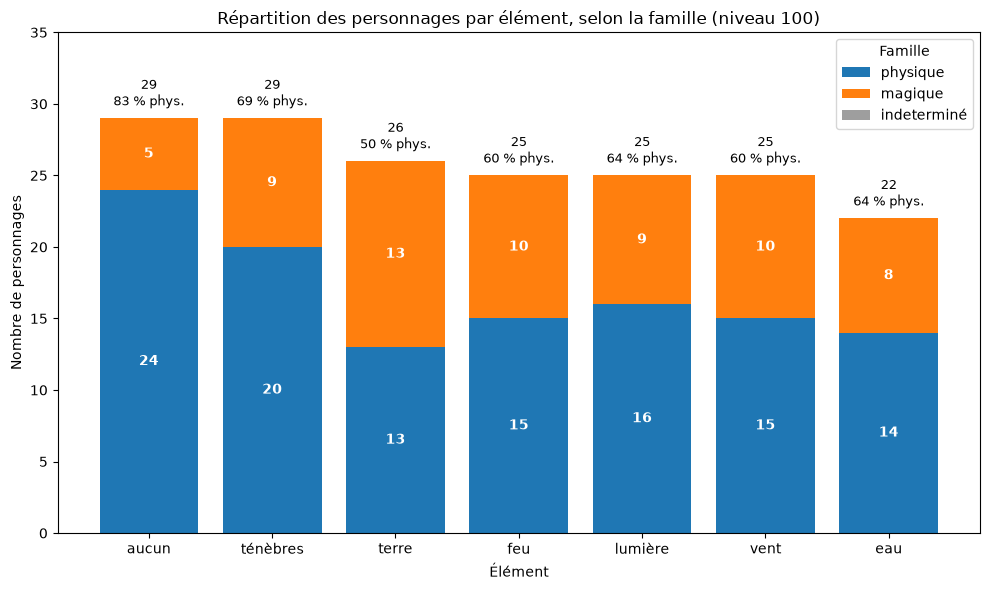

In [9]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]
FAMILLES = ["physique", "magique", "indetermine"]
COULEURS = {"physique": "#1f77b4", "magique": "#ff7f0e", "indetermine": "#9e9e9e"}

ELEMENTS = [r["element"] for r in
            df_perso_100.groupBy("element").count().orderBy(F.desc("count"), "element").collect()]

df_perso_100 = df_perso_100.withColumn(
    "faible_partout", (F.col("ATK") < 2300) & (F.col("MATK") < 2300)
)


tab = (
    df_perso_100.groupBy("element")
    .pivot("famille", FAMILLES).count().na.fill(0)
    .withColumn("total", F.col("physique") + F.col("magique") + F.col("indetermine"))
    .toPandas().set_index("element").loc[ELEMENTS]
)


fig, ax = plt.subplots(figsize=(10, 6))
bas = np.zeros(len(tab))
for fam in FAMILLES:
    ax.bar(tab.index, tab[fam], bottom = bas, color = COULEURS[fam], label=fam.replace("indetermine", "indeterminé"))

    for i, (v, b) in enumerate(zip(tab[fam], bas)):
        if v >= 3:                                  # pas d'étiquette dans un segment minuscule
            ax.text(i, b + v / 2, int(v), ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    bas += tab[fam].values

for i, (el, row) in enumerate(tab.iterrows()):
    pct = row["physique"] / (row["physique"] + row["magique"]) * 100
    ax.text(i, row["total"] + 0.6, f"{int(row['total'])}\n{pct:.0f} % phys.",
            ha="center", va="bottom", fontsize=9)

ax.set_ylim(0, tab["total"].max() + 6)
ax.set_title("Répartition des personnages par élément, selon la famille (niveau 100)")
ax.set_xlabel("Élément")
ax.set_ylabel("Nombre de personnages")
ax.legend(title="Famille")
plt.tight_layout()
plt.show()

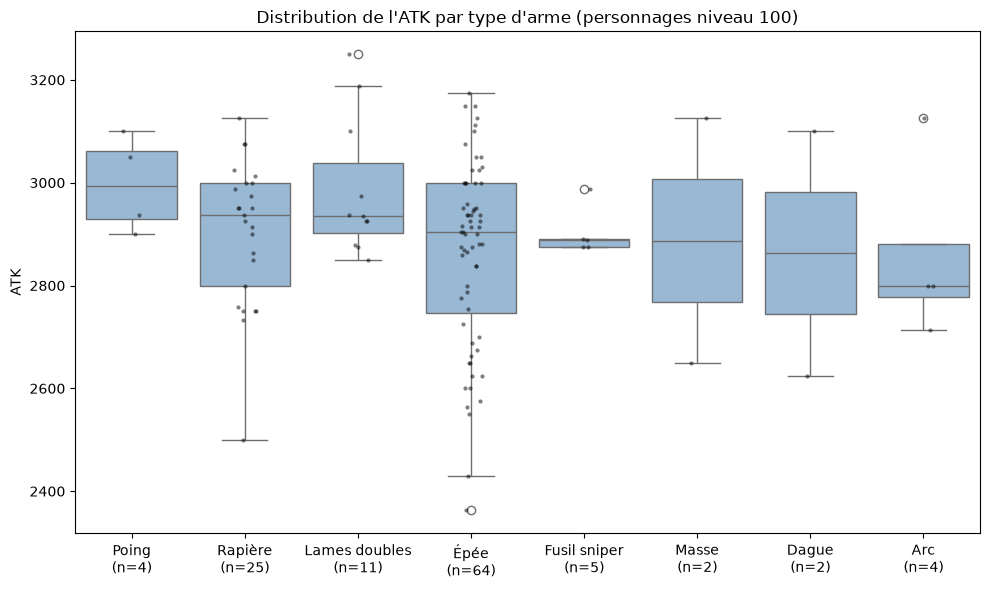

In [10]:
pdf = (
    df_perso_100
    .filter(F.col("famille") == "physique")
    .select("nom", "arme", "ATK")
    .toPandas()
)
ordre = pdf.groupby("arme")["ATK"].median().sort_values(ascending=False).index
effectifs = pdf["arme"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=pdf, x="arme", y="ATK", order=ordre, ax=ax, color="#8fb8de")
sns.stripplot(data=pdf, x="arme", y="ATK", order=ordre, ax=ax,
              color="black", size=3, alpha=0.5)

ax.set_xticks(range(len(ordre)))
ax.set_xticklabels([f"{a}\n(n={effectifs[a]})" for a in ordre])
ax.set_title("Distribution de l'ATK par type d'arme (personnages niveau 100)")
ax.set_xlabel("")
ax.set_ylabel("ATK")
plt.tight_layout()
plt.show()


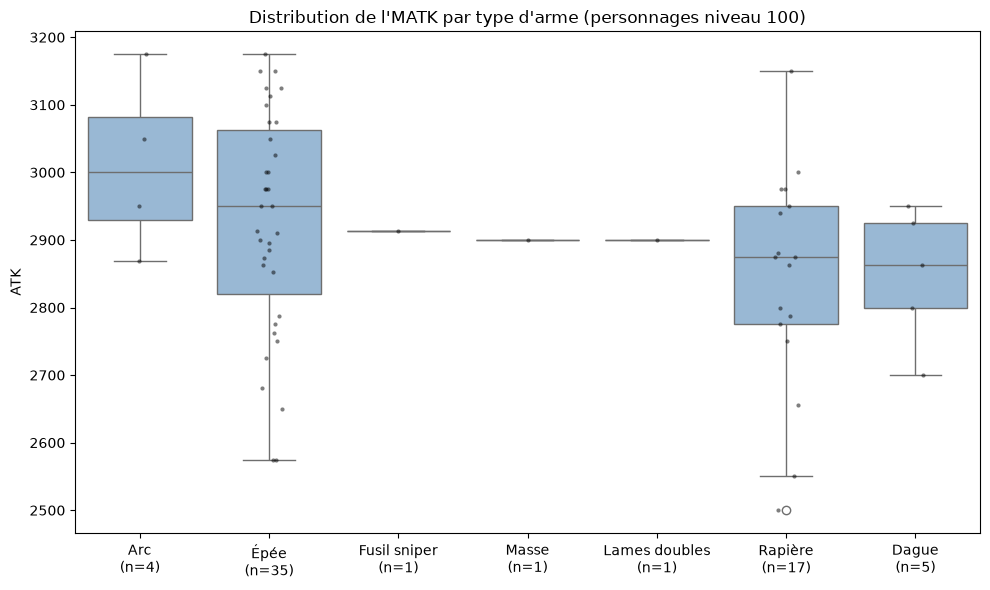

In [11]:
pdf = (
    df_perso_100
    .filter(F.col("famille") == "magique")
    .select("nom", "arme", "MATK")
    .toPandas()
)

ordre = pdf.groupby("arme")["MATK"].median().sort_values(ascending=False).index
effectifs = pdf["arme"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=pdf, x="arme", y="MATK", order=ordre, ax=ax, color="#8fb8de")
sns.stripplot(data=pdf, x="arme", y="MATK", order=ordre, ax=ax,
              color="black", size=3, alpha=0.5)

ax.set_xticks(range(len(ordre)))
ax.set_xticklabels([f"{a}\n(n={effectifs[a]})" for a in ordre])
ax.set_title("Distribution de l'MATK par type d'arme (personnages niveau 100)")
ax.set_xlabel("")
ax.set_ylabel("ATK")
plt.tight_layout()
plt.show()


### Graphique : Les stats

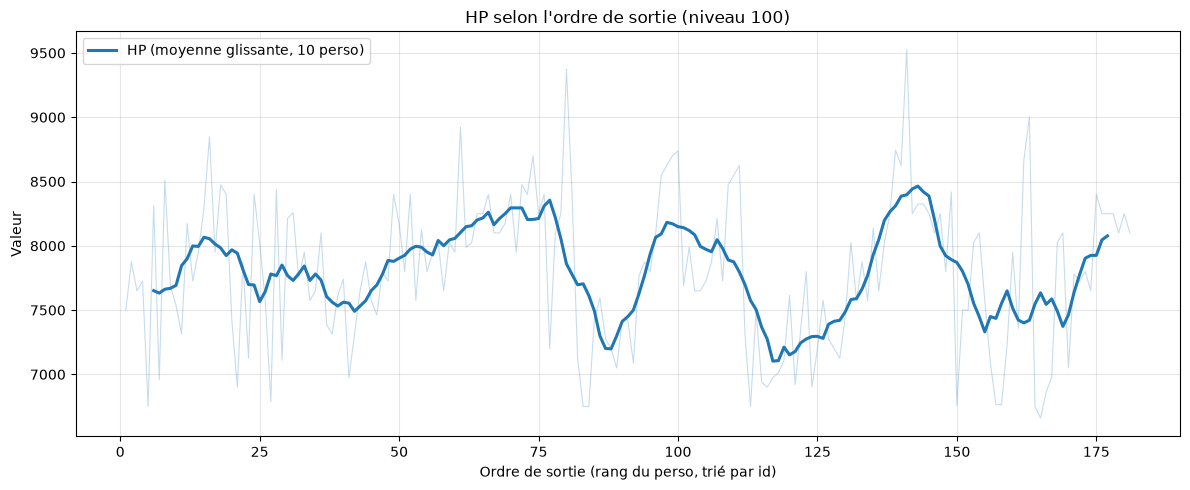

In [12]:
pdf = df_perso_100.select("id", "nom_complet", "HP").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("HP", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("HP selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

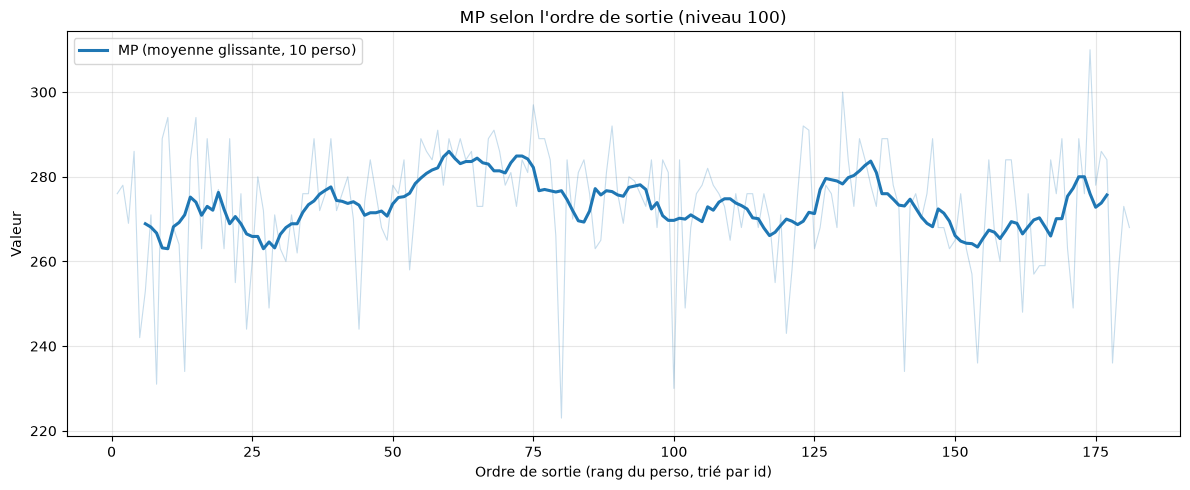

In [13]:
pdf = df_perso_100.select("id", "nom_complet", "MP").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("MP", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("MP selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

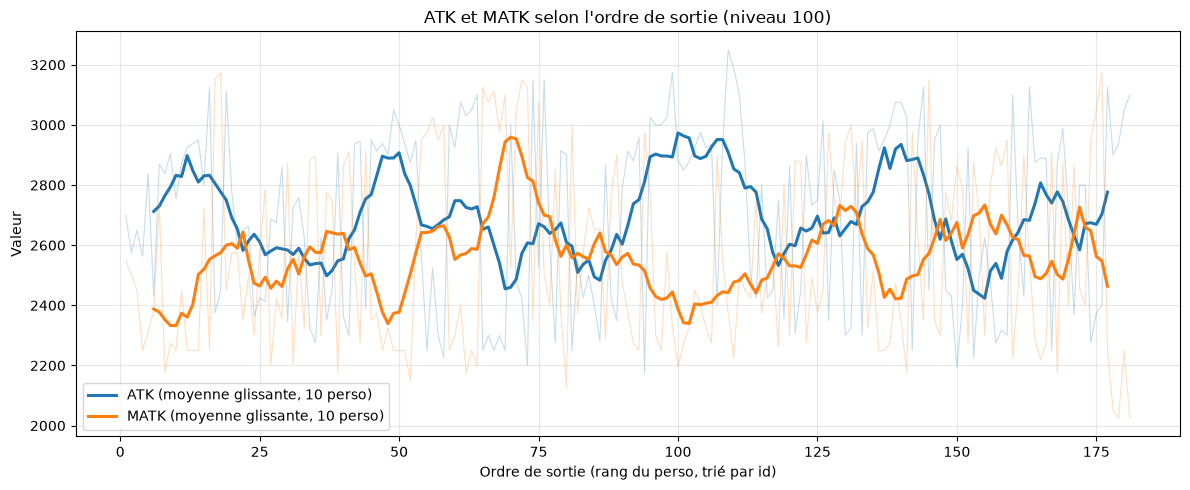

In [14]:
pdf = df_perso_100.select("id", "nom_complet", "ATK", "MATK").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("ATK", "#1f77b4"), ("MATK", "#ff7f0e")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("ATK et MATK selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

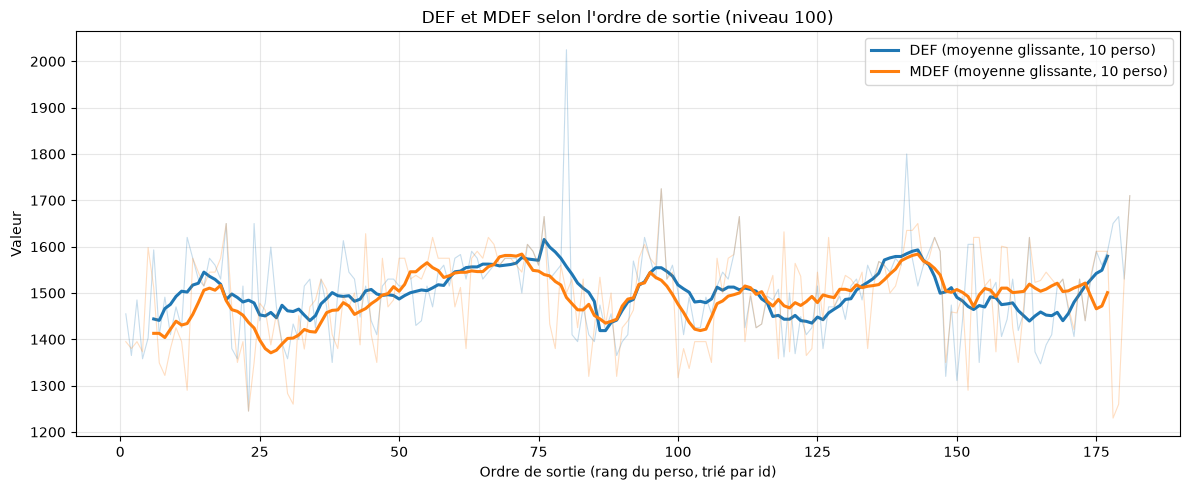

In [15]:
pdf = df_perso_100.select("id", "nom_complet", "DEF", "MDEF").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("DEF", "#1f77b4"), ("MDEF", "#ff7f0e")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("DEF et MDEF selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

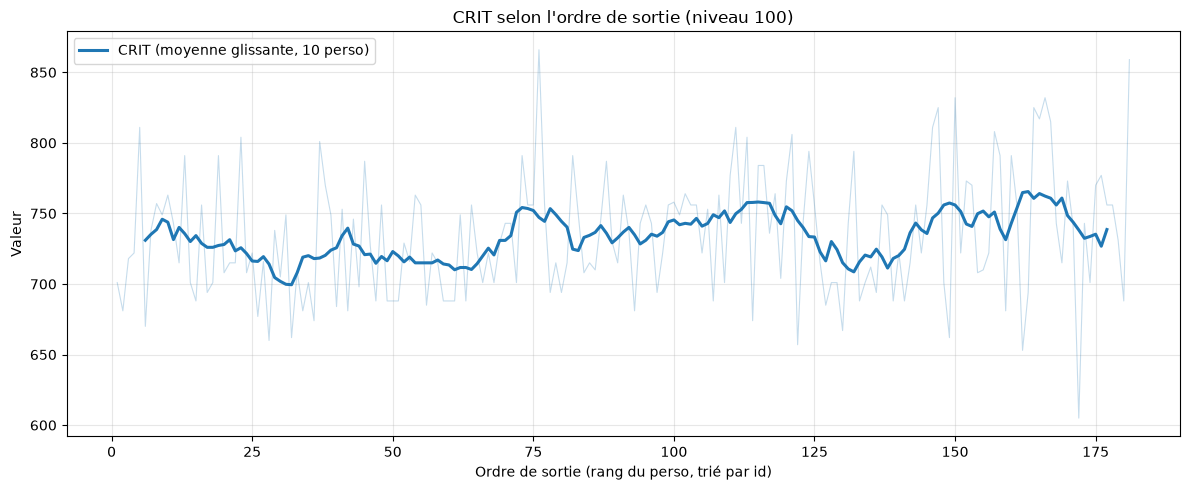

In [16]:
pdf = df_perso_100.select("id", "nom_complet", "CRIT").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("CRIT", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("CRIT selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

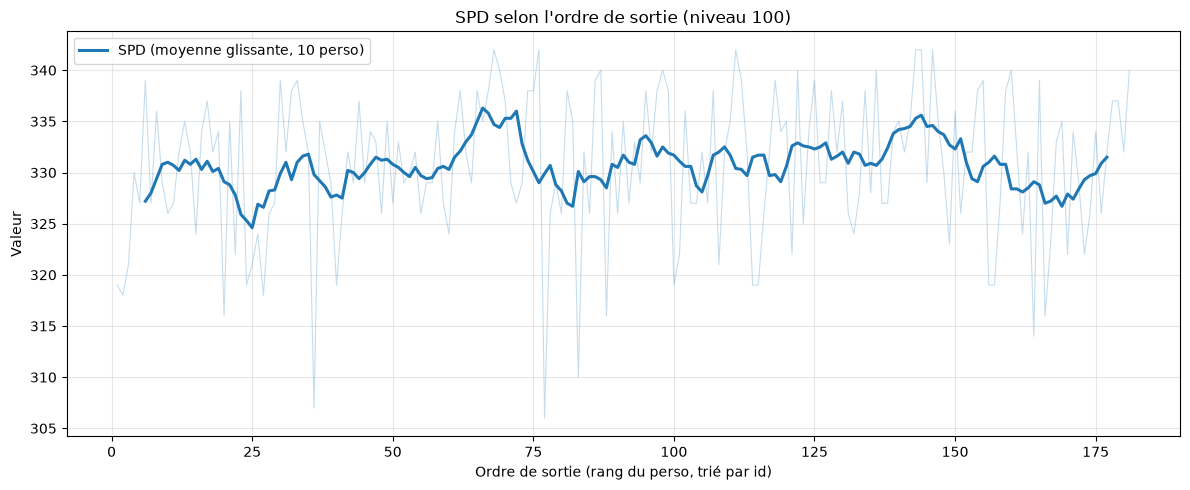

In [17]:
pdf = df_perso_100.select("id", "nom_complet", "SPD").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("SPD", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("SPD selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

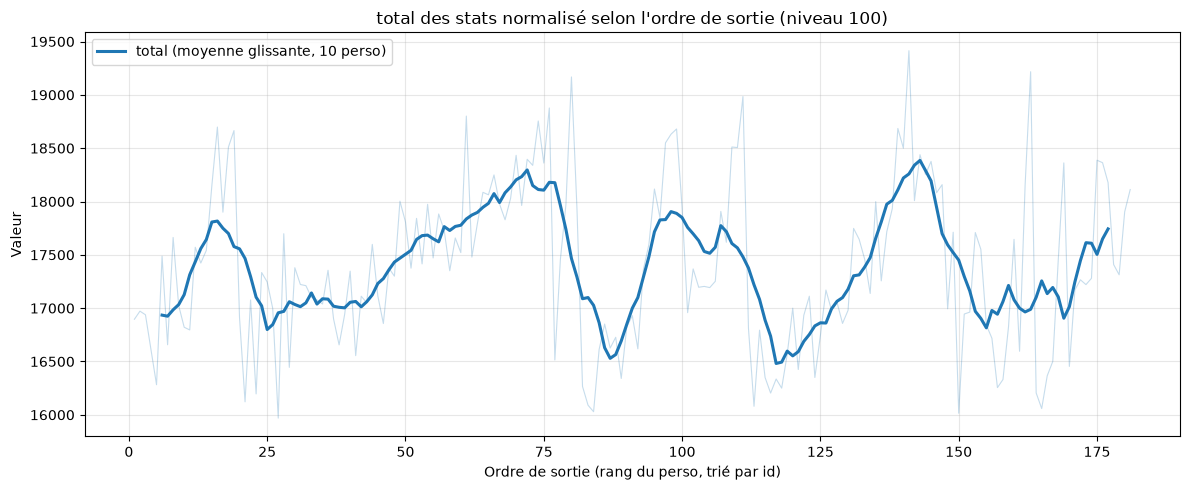



Comme les HP représente environ 45% du total des stats, alors on normalise sur le graphique d'après



In [18]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT" ,"SPD"]

df_total = df_perso_100.withColumn("total" , sum(F.col(i) for i in STATS))


pdf = df_total.select("id", "nom_complet", "total").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("total", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("total des stats  selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n\nComme les HP représente environ 45% du total des stats, alors on normalise sur le graphique d'après\n")

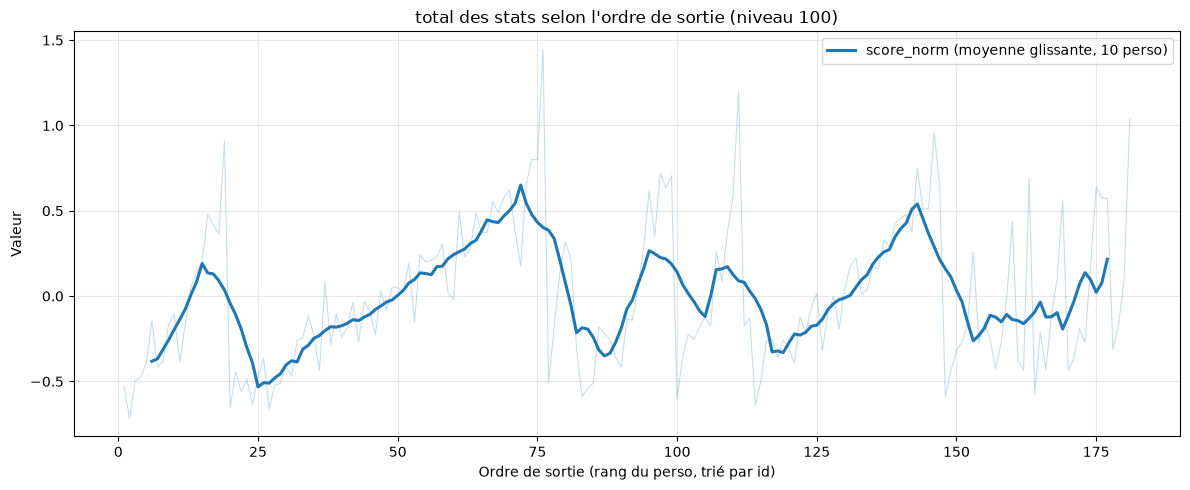

In [19]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT" ,"SPD"]

ms = df_perso_100.agg(
    *[F.avg(s).alias(f"{s}_moy") for s in STATS],
    *[F.stddev(s).alias(f"{s}_std") for s in STATS],
).first().asDict()

df_total = (
    df_perso_100
    .withColumn("total", sum(F.col(s) for s in STATS))
    .withColumn("score_norm",
        sum((F.col(s) - ms[f"{s}_moy"]) / ms[f"{s}_std"] for s in STATS) / len(STATS))
)

pdf = df_total.select("id", "nom_complet", "score_norm").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("score_norm", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("total des stats normalisé selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

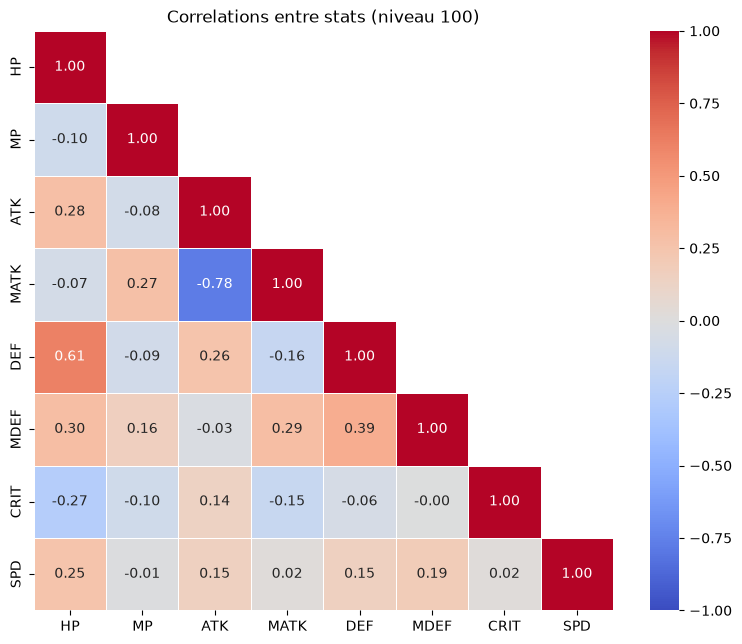

=== Paires classé ===


,stat_1,stat_2,r
5,MATK,ATK,-0.779214
6,DEF,HP,0.610690
14,MDEF,DEF,0.391921
10,MDEF,HP,0.295088
13,MDEF,MATK,0.289679
1,ATK,HP,0.282629
4,MATK,MP,0.274057
15,CRIT,HP,-0.273299
8,DEF,ATK,0.255483
21,SPD,HP,0.254456


In [20]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def matrice_correlation(df, cols):
    paires = list(combinations(cols, 2))
    ligne = df.agg(*[F.corr(a, b).alias(f"{a}__{b}") for a, b in paires]).first()
    mat = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for a, b in paires:
        mat.loc[a, b] = mat.loc[b, a] = ligne[f"{a}__{b}"]
    return mat

corr = matrice_correlation(df_perso_100, STATS)

fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm", vmin = -1, vmax=1, center = 0, square = True, linewidths=0.5, ax= ax)
ax.set_title("Correlations entre stats (niveau 100)")
plt.tight_layout()
plt.show()

print("=== Paires classé ===")
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

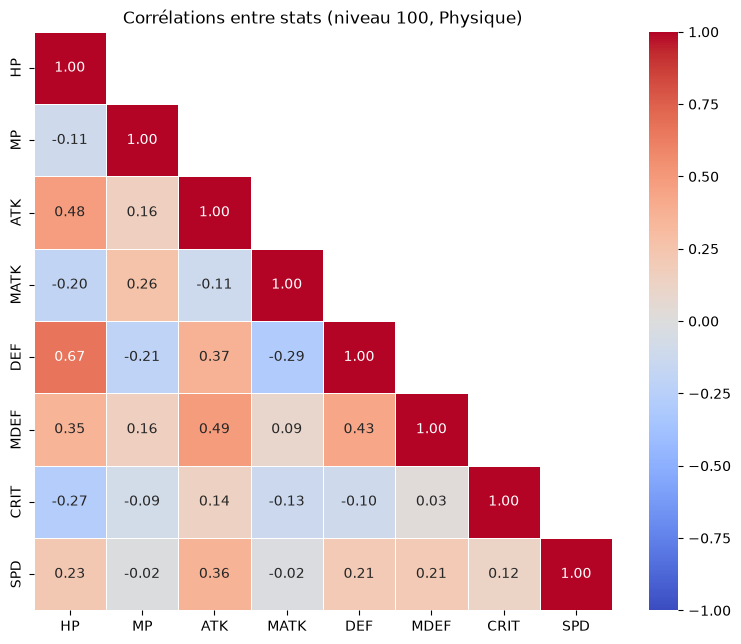

,stat_1,stat_2,r
6,DEF,HP,0.668345
12,MDEF,ATK,0.486909
1,ATK,HP,0.480971
14,MDEF,DEF,0.433558
8,DEF,ATK,0.369171
23,SPD,ATK,0.361449
10,MDEF,HP,0.353004
9,DEF,MATK,-0.291634
15,CRIT,HP,-0.266590
4,MATK,MP,0.258014


In [21]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]


corr = matrice_correlation(df_perso_100.filter(F.col("famille") == "physique"), STATS)

# Heatmap (triangle du bas seulement : la matrice est symétrique)
fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Corrélations entre stats (niveau 100, Physique)")
plt.tight_layout()
plt.show()

# Les paires classées, pour lire les chiffres sans la couleur
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

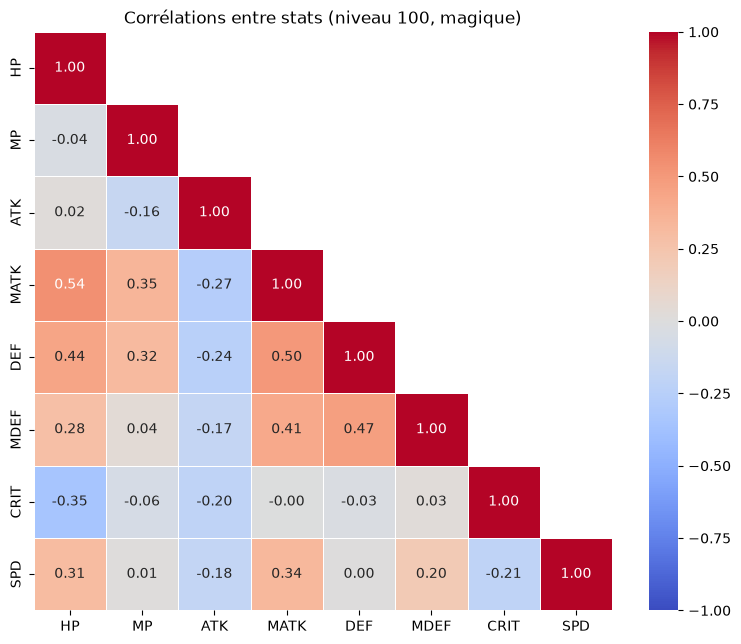

,stat_1,stat_2,r
3,MATK,HP,0.543776
9,DEF,MATK,0.503346
14,MDEF,DEF,0.474008
6,DEF,HP,0.443744
13,MDEF,MATK,0.414205
15,CRIT,HP,-0.345737
4,MATK,MP,0.345428
24,SPD,MATK,0.335562
7,DEF,MP,0.316342
21,SPD,HP,0.309560


In [22]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

corr = matrice_correlation(df_perso_100.filter(F.col("famille") == "magique"), STATS)

# Heatmap (triangle du bas seulement : la matrice est symétrique)
fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Corrélations entre stats (niveau 100, magique)")
plt.tight_layout()
plt.show()

# Les paires classées, pour lire les chiffres sans la couleur
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

=== Pas de corrélation entre les élément et les stats ===
--- le graph sert surtout à montrer qu'il n'y a pas de corrélation ---


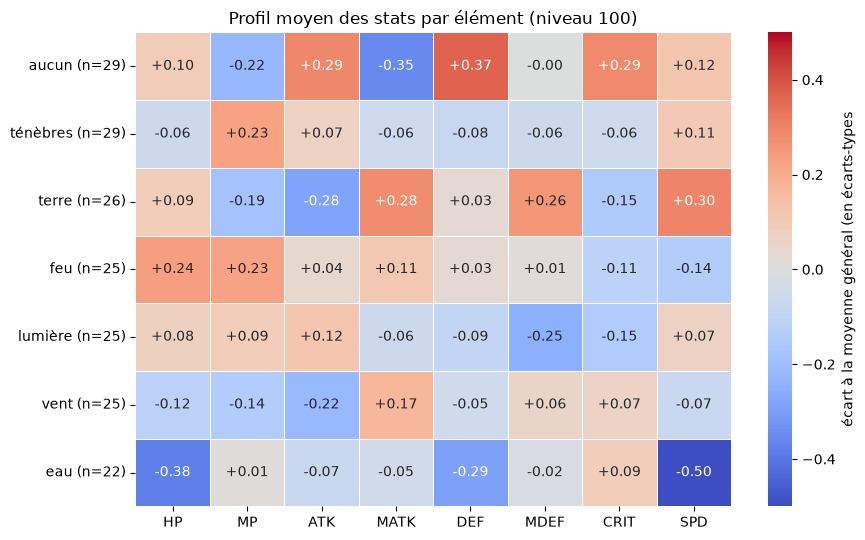

In [23]:
print("=== Pas de corrélation entre les élément et les stats ===\n--- le graph sert surtout à montrer qu'il n'y a pas de corrélation ---")

ms = df_perso_100.agg(
    *[F.avg(s).alias(f"{s}_moy") for s in STATS],
    *[F.stddev(s).alias(f"{s}_std") for s in STATS]
).first().asDict()

prof = (
    df_perso_100.groupBy("element")
    .agg(*[F.avg(s).alias(s) for s in STATS], F.count("*").alias("n"))
    .select("element", "n", *[((F.col(s) - ms[f"{s}_moy"]) / ms[f"{s}_std"]).alias(s) for s in STATS])
    .toPandas().set_index("element").loc[ELEMENTS]
)
labels = [f"{e} (n={int(prof.loc[e, 'n'])})" for e in prof.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(prof[STATS].set_axis(labels), annot=True, fmt="+.2f", cmap="coolwarm", vmin = -0.5, vmax=0.5, center = 0, linewidths = 0.5, ax=ax, cbar_kws={"label": "écart à la moyenne général (en écarts-types"})

ax.set_title("Profil moyen des stats par élément (niveau 100)")
plt.tight_layout()
plt.show()

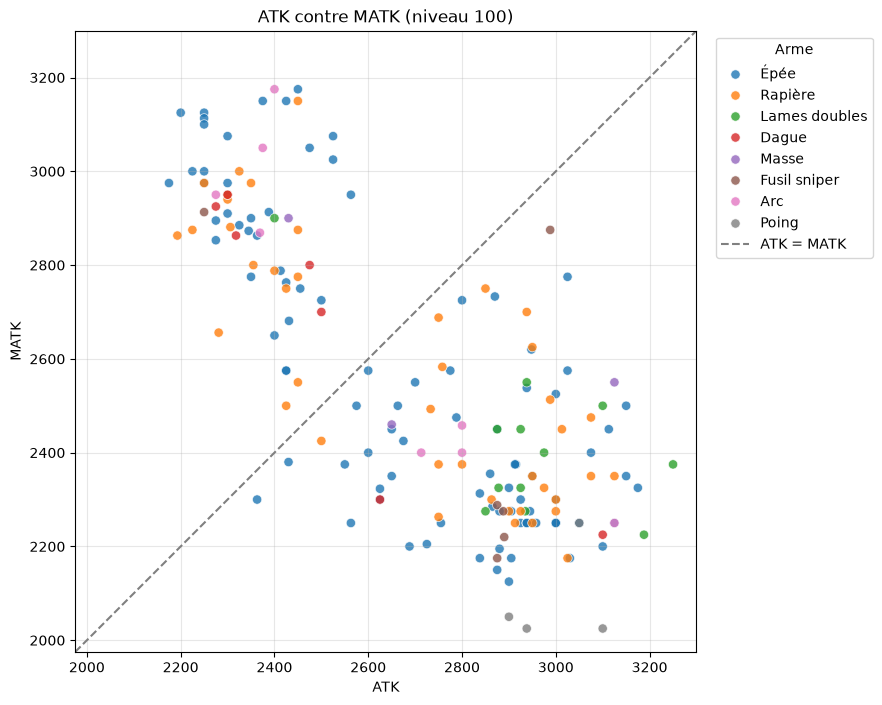

In [24]:
pdf = df_perso_100.select("nom_complet", "arme", "famille", "ATK", "MATK").toPandas()

fig, ax = plt.subplots(figsize=(8.5, 8))
sns.scatterplot(data=pdf, x="ATK", y = "MATK",hue = "arme",  ax = ax, s=45, alpha = 0.8, palette="tab10")

bas = pdf[["ATK", "MATK"]].min().min() - 50
haut = pdf[["ATK", "MATK"]].max().max() + 50
ax.plot([bas, haut], [bas, haut], linestyle="--", color="grey", label="ATK = MATK")

ax.set_xlim(bas, haut); ax.set_ylim(bas, haut)
ax.set_aspect("equal")                       # axes à la même échelle
ax.set_title("ATK contre MATK (niveau 100)")
ax.grid(alpha=0.3)
ax.legend(title="Arme", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Top 5 des meilleur et pire

In [25]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def top_5(df, stat, n=5):
    seuil_haut = (
        df.orderBy(F.desc(stat))
        .limit(n)
        .agg(F.min(stat))
        .first()[0]
    )

    seuil_bas = (
        df.orderBy(F.asc(stat))
        .limit(n)
        .agg(F.max(stat))
        .first()[0]
    )

    top = (
        df.filter(F.col(stat) >= seuil_haut)
        .select("nom_complet", F.col(stat).alias("valeur"))
        .orderBy(F.desc("valeur"), "nom_complet")
    )

    bot = (
        df.filter(F.col(stat) <= seuil_bas)
        .select("nom_complet", F.col(stat).alias("valeur"))
        .orderBy(F.asc("valeur"), "nom_complet")
    )

    return top, bot



for s in STATS:
    top, bot = top_5(df_perso_100, s)
    print(f"=== {s} : meilleur ===");   top.show(truncate=False)
    print(f"=== {s} : pires ===");  bot.show(truncate=False)
    print("--------------------------------------------------------\n")

=== HP : meilleur ===
+---------------------------------------------------+------+
|nom_complet                                        |valeur|
+---------------------------------------------------+------+
|[Sous le ciel neigeux, les souvenirs] Administrator|9525  |
|[Le Chevalier aux bras de fer] Entokia             |9375  |
|[L'inébranlable Master Macer] Lisbeth              |9000  |
|[La déesse des abîmes] Eydis                       |8925  |
|[Le Chevalier de l’Intégrité de glace] Eugeo       |8850  |
+---------------------------------------------------+------+

=== HP : pires ===
+---------------------------------+------+
|nom_complet                      |valeur|
+---------------------------------+------+
|[Je veux donc je peux] Sinon     |6660  |
|[Détermination ardente] Tizée    |6750  |
|[Le bourgeon de la justice] Lonie|6750  |
|[L’éclair intense] Asuna         |6750  |
|[Surmonter le passé] Sinon       |6750  |
|[Torrent de techniques] Kirito   |6750  |
+---------------------

### Les compétences

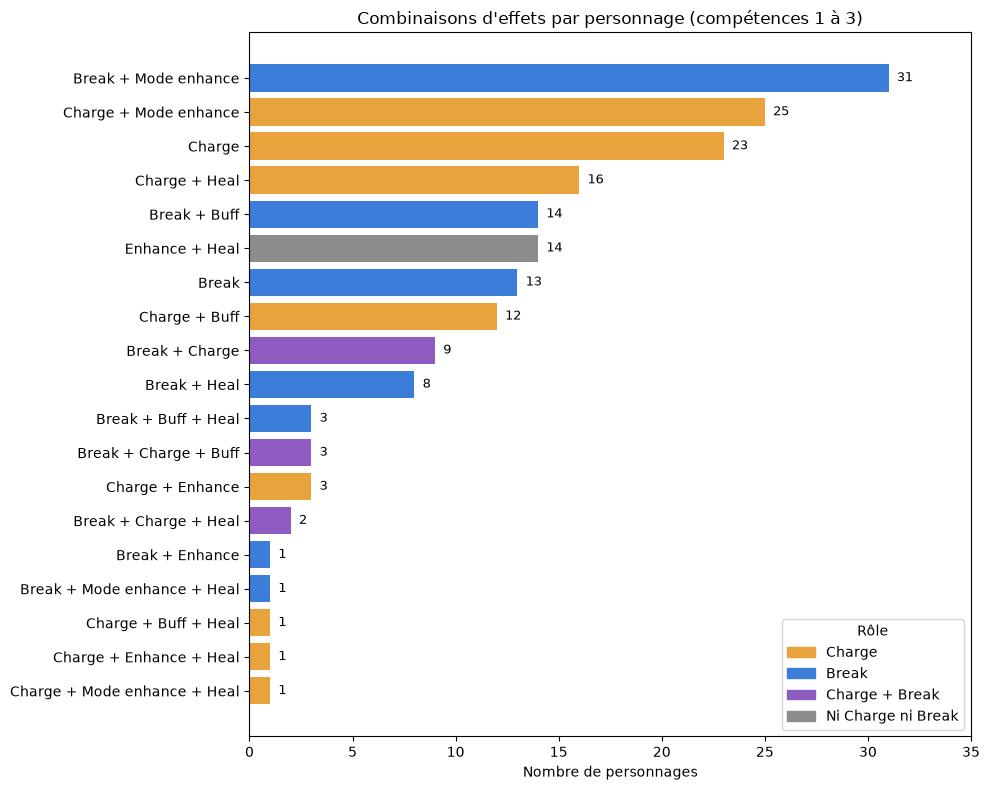

In [26]:
from functools import reduce

SLOTS = ["competence_1", "competence_2", "competence_3"]

def competence_slot(slot):
    c = F.col(f"competences.{slot}")
    return df_perso.select(
        F.col("id").alias("perso_id"),
        F.lit(slot).alias("slot"),
        c["categorie"].alias("categorie"),
        F.element_at(c["niveaux"], -1)["description"].alias("description"),   # dernier niveau
    )

df_comp = reduce(lambda a, b: a.unionByName(b), [competence_slot(s) for s in SLOTS])


BOOST = r"Capacité d'un allié à (charger|briser)"      # le vrai « Enhance »
cat, desc = F.col("categorie"), F.col("description")

def contient(motif):       # False (et non null) quand la description est vide
    return F.coalesce(desc.rlike(motif), F.lit(False))

TAGS = ["Break", "Charge", "Mode enhance", "Enhance", "Buff", "Heal"]

df_tags = df_comp.select(
    "perso_id",
    (contient(r"Brise la Volonté")     | cat.contains("BREAK")).alias("Break"),
    (contient(r"Charge la Volonté de") | cat.contains("CHARGE")).alias("Charge"),
    (cat == "ENHANCE_MODE").alias("Mode enhance"),
    contient(BOOST).alias("Enhance"),
    (cat.startswith("BUFF") & ~contient(BOOST)).alias("Buff"),
    (contient(r"Soins HP")             | cat.contains("HEAL")).alias("Heal"),
)

df_perso_tags = (
    df_tags.groupBy("perso_id")
    .agg(*[F.max(F.col(t).cast("int")).alias(t) for t in TAGS])     # 1 si au moins une compétence l'a
    .withColumn("combo", F.concat_ws(" + ", *[F.when(F.col(t) == 1, F.lit(t)) for t in TAGS]))
    .withColumn("combo", F.when(F.col("combo") == "", "(aucun)").otherwise(F.col("combo")))
    .withColumn("role",
        F.when((F.col("Charge") == 1) & (F.col("Break") == 1), "Charge + Break")
         .when(F.col("Charge") == 1, "Charge")
         .when(F.col("Break") == 1, "Break")
         .otherwise("Ni Charge ni Break"))
)


cnt = (df_perso_tags.groupBy("combo", "role").count()
       .orderBy(F.desc("count"), "combo").toPandas())

COULEURS_ROLE = {"Charge": "#e8a33d", "Break": "#3b7dd8",
                 "Charge + Break": "#8e5bc0", "Ni Charge ni Break": "#8c8c8c"}

cnt_plot = cnt.iloc[::-1]                       # le plus grand en haut
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(cnt_plot["combo"], cnt_plot["count"], color=cnt_plot["role"].map(COULEURS_ROLE))
for y, v in enumerate(cnt_plot["count"]):
    ax.text(v + 0.4, y, int(v), va="center", fontsize=9)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COULEURS_ROLE.values()]
ax.legend(handles, COULEURS_ROLE.keys(), title="Rôle", loc="lower right")
ax.set_title("Combinaisons d'effets par personnage (compétences 1 à 3)")
ax.set_xlabel("Nombre de personnages")
ax.set_xlim(0, cnt["count"].max() + 4)
plt.tight_layout()
plt.show()

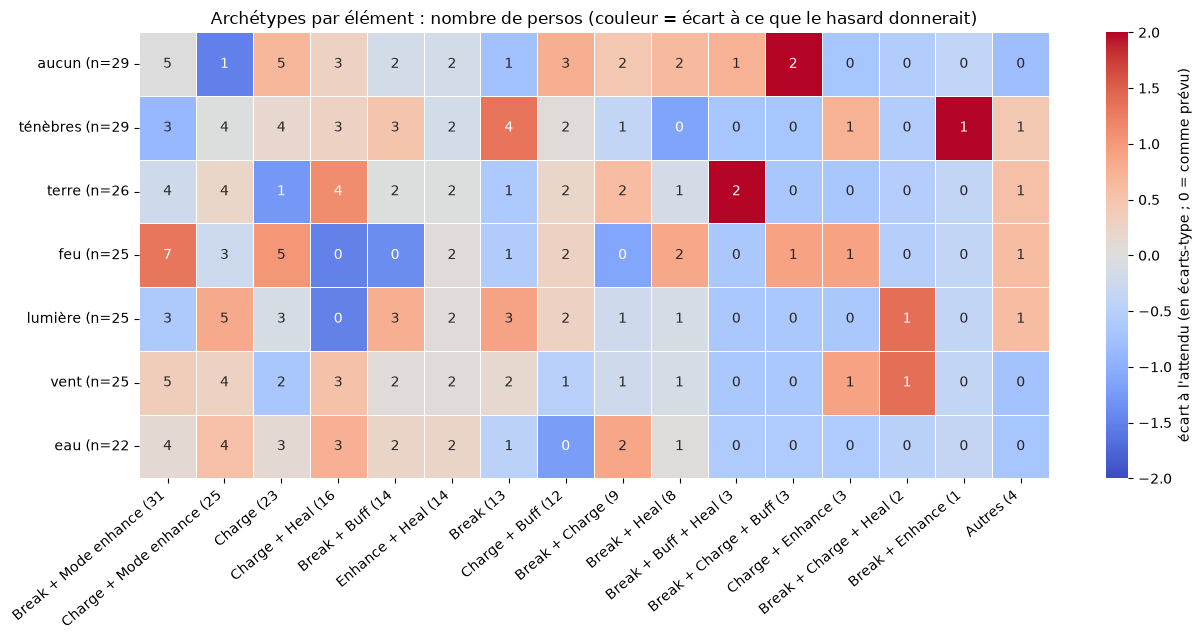

In [28]:
df_el = df_perso_tags.join(df_perso.select(F.col("id").alias("perso_id"), "element"), "perso_id")

N_TOP = 15
combos_top = [r["combo"] for r in
              df_el.groupBy("combo").count().orderBy(F.desc("count"), "combo").limit(N_TOP).collect()]

df_el = df_el.withColumn(
    "archetype", F.when(F.col("combo").isin(combos_top), F.col("combo")).otherwise("Autres")
)

colonnes = combos_top + ["Autres"]
tab = (
    df_el.groupBy("element").pivot("archetype", colonnes).count().na.fill(0).toPandas().set_index("element").loc[ELEMENTS, colonnes]
)

# Ce que le hasard donnerait si l'élément n'influençait pas l'archétype
attendu = pd.DataFrame(np.outer(tab.sum(axis=1), tab.sum(axis=0)) / tab.values.sum(), index=tab.index, columns=tab.columns)
ecart = (tab - attendu) / np.sqrt(attendu)

labels_lignes = [f"{e} (n={ int(tab.loc[e].sum()) }" for e in tab.index]
labels_cols = [f"{c} ({int(tab[c].sum())}" for c in tab.columns]

fig, ax = plt.subplots(figsize = (13, 6.5))
sns.heatmap(ecart.set_axis(labels_lignes).set_axis(labels_cols, axis=1), annot=tab.values, fmt="d", cmap="coolwarm", vmin=-2, vmax = 2, center=0, linewidths=0.5, ax=ax, cbar_kws={"label": "écart à l'attendu (en écarts-type ; 0 = comme prévu)"})
ax.set_title("Archétypes par élément : nombre de persos (couleur = écart à ce que le hasard donnerait)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

+---+
|p  |
+---+
+---+



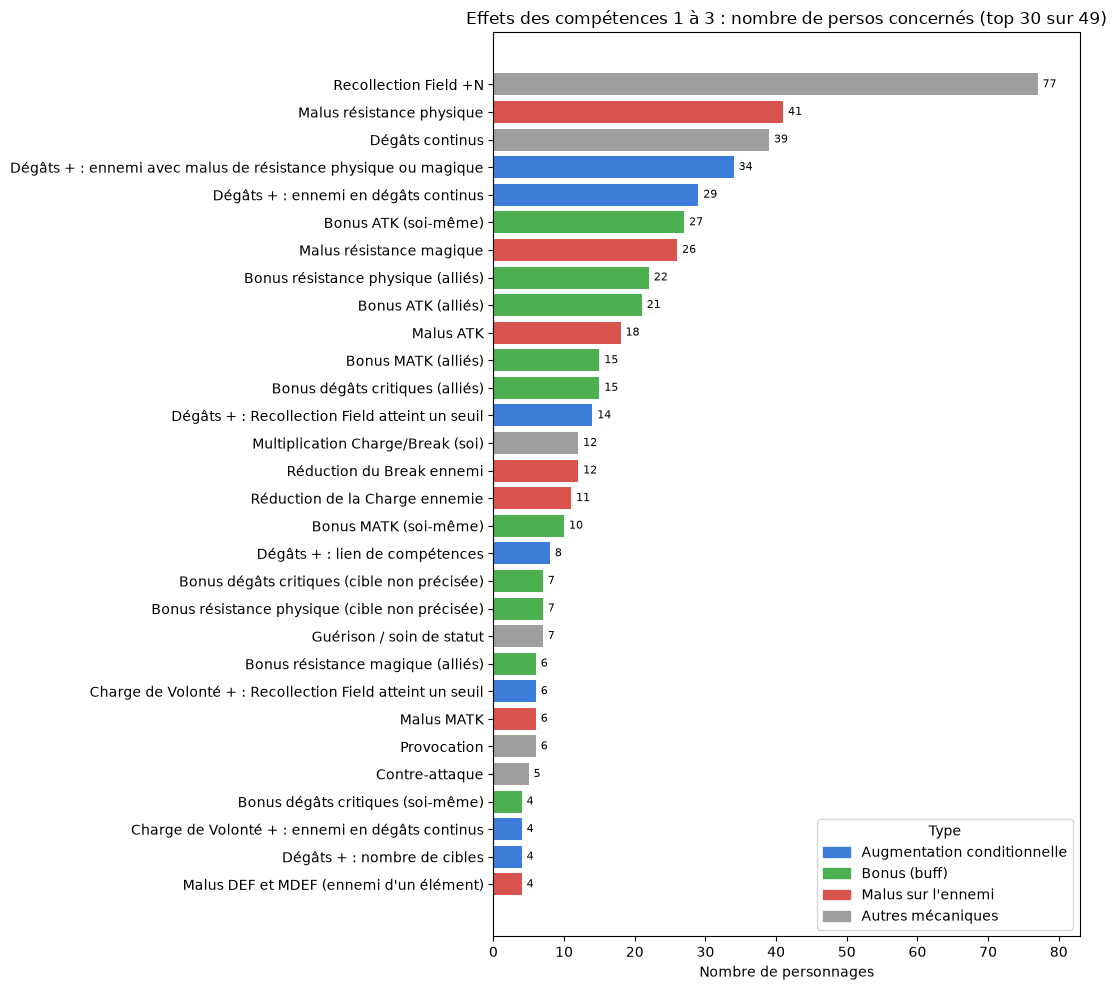

In [27]:
SLOTS = ["competence_1", "competence_2", "competence_3"]      #
# ["incarnation"] pour la section dédiée

def phrases_du_slot(slot):
    c = F.col(f"competences.{slot}")
    return df_perso.select(
        F.col("id").alias("perso_id"), "element", F.lit(slot).alias("slot"),
        F.element_at(c["niveaux"], -1)["description"].alias("description"),   # niveau max
    )

SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"

def normaliser(col):
    c = F.regexp_replace(col, r"tour\(s\)", "tours")
    c = F.regexp_replace(c, r"\s*\([^()]*(tours|maximum)[^()]*\)", "")      # durées et « maximum »
    c = F.regexp_replace(c, r"\s*\((faible|moyenne|forte|énorme)\)", "")    # intensités
    c = F.regexp_replace(c, r"\d+(,\d+)?", "N")                             # nombres
    c = F.regexp_replace(c, r"\s+", " ")
    c = F.regexp_replace(c, r"[\s.,;]+$", "")
    return F.trim(c)

EXCLUS = (r"^(Brise la Volonté|Charge la Volonté de|Entre soi-même en mode|Capacité d'un allié|Soins HP"
          r"|Attaque (tranchante|magique|perçante|de frappe) sur (un ennemi|tous les ennemis)$"
          r"|Temps de préparation|Rotation|\（仮\）|$)")

df_phr = (
    reduce(lambda a, b: a.unionByName(b), [phrases_du_slot(s) for s in SLOTS])
    .select("perso_id", "element", "slot", F.explode(F.split(F.trim("description"), SPLIT)).alias("phrase"))
    .withColumn("p", normaliser(F.col("phrase")))
    .filter(~F.col("p").rlike(EXCLUS))
)


p = F.col("p")
vide = F.array().cast("array<string>")

# a) « Augmentation de … » : effet augmenté + condition (inchangé)
est_boost = p.rlike(r"^Augmentation (des dégâts|de la Charge de Volonté|de la capacité à briser|du Break de Volonté)")
effet_boost = (F.when(p.rlike(r"^Augmentation des dégâts"), "Dégâts")
                .when(p.rlike(r"^Augmentation de la Charge"), "Charge de Volonté")
                .otherwise("Break de Volonté"))
condition = (
    F.when(p.contains("subissant des dégâts continus"), "ennemi en dégâts continus")
     .when(p.contains("subissant un malus de résistance"),
           F.concat(F.lit("ennemi avec malus de résistance "),
                    F.regexp_extract(p, r"malus de résistance\s*(.*)$", 1)))
     .when(p.contains("Recollection Field"), "Recollection Field atteint un seuil")
     .when(p.contains("lien de compétences"), "lien de compétences")
     .when(p.contains("nombre de cibles"), "nombre de cibles")
     .when(p.rlike(r"(quand|lorsque) le bonus"), "bonus d'ATK ou de critique atteint un seuil")
     .otherwise("autre condition")
)
etiq_boost = F.when(est_boost, F.array(F.concat(effet_boost, F.lit(" + : "), condition))).otherwise(vide)

# Toutes les règles qui correspondent, pas seulement la première
def correspondances(regles):
    return F.filter(F.array(*[F.when(p.rlike(r), F.lit(n)) for r, n in regles]),
                    lambda x: x.isNotNull())

# b) Effets sans cible
REGLES = [
    (r"^Résistances? physique( et magique)? -N%", "Malus résistance physique"),
    (r"^Résistance magique (sur l'ennemi )?-N%|^Résistances? physique et magique -N%"
     r"|^Résistance physique -N% et résistance magique -N%", "Malus résistance magique"),
    (r"^Résistance à l'élément [^ ]+ -N%|^La résistance à l'élément [^ ]+ diminue"
     r"|et de N% la résistance à l'élément", "Malus résistance d'élément"),
    (r"^De plus, DEF et MDEF -N% si l'ennemi", "Malus DEF et MDEF (ennemi d'un élément)"),
    (r"^ATK -N%", "Malus ATK"),
    (r"^MATK -N%", "Malus MATK"),
    (r"^Réduit de N% le Break de Volonté de l'ennemi", "Réduction du Break ennemi"),
    (r"^Réduit (de N% )?la Charge de Volonté (ennemie|de l'ennemi)|^Charge de Volonté de l'ennemi -N%", "Réduction de la Charge ennemie"),
    (r"^Inflige des dégâts continus", "Dégâts continus"),
    (r"^Recollection Field", "Recollection Field +N"),
    (r"^Provoque l'ennemi", "Provocation"),
    (r"^Inflige une contre-attaque", "Contre-attaque"),
    (r"^(Guérit|Soigne|Guérison)", "Guérison / soin de statut"),
    (r"^Multiplie (sa|le|la) |^Capacité à charger", "Multiplication Charge/Break (soi)"),
    (r"^Attaque .*N% de dégâts de HP maximum", "Attaque avec coût en HP"),
    (r"^Et attaque ", "Attaque supplémentaire"),
    (r"^En contrepartie|^Résistance [^ ]+ sur soi-même -N%", "Malus en contrepartie"),
]

# c) Bonus : on cherche chaque stat citée dans la phrase
BONUS = [
    (r"(?<![A-Za-z])ATK", "Bonus ATK"),                 # pas de « M » devant : MATK est à part
    (r"MATK", "Bonus MATK"),
    (r"[Rr]ésistances? physique", "Bonus résistance physique"),
    (r"[Rr]ésistances? (physique et )?magique", "Bonus résistance magique"),
    (r"[Rr]ésistance (d'|à l')élément", "Bonus résistance d'élément"),
    (r"[Dd]égâts critiques", "Bonus dégâts critiques"),
    (r"Taux de coup critique", "Bonus taux de critique"),
    (r"Taux d'esquive", "Bonus esquive"),
]
cible = (F.when(p.contains("soi-même"), " (soi-même)")
          .when(p.rlike("alliés?"), " (alliés)")
          .otherwise(" (cible non précisée)"))
est_bonus = ~est_boost & p.rlike(r"\+N%|en augmentant de N%|^Augmentation de N% des dégâts critiques")
etiq_bonus = F.when(est_bonus,
                    F.transform(correspondances(BONUS), lambda n: F.concat(n, cible))).otherwise(vide)

# Une ligne par effet (une phrase peut en avoir plusieurs)
toutes = F.concat(etiq_boost, correspondances(REGLES), etiq_bonus)
df_eff = (df_phr
          .withColumn("effets", F.when(F.size(toutes) == 0, F.array(F.lit("Autre"))).otherwise(toutes))
          .withColumn("effet", F.explode("effets"))
          .drop("effets"))

df_eff.filter(F.col("effet") == "Autre").select("p").distinct().show(truncate=False)   # doit être vide


global_ = (df_eff.groupBy("effet").agg(F.countDistinct("perso_id").alias("nb_persos"))
           .orderBy(F.desc("nb_persos"), "effet").toPandas())

def categorie(e):
    if " + : " in e: return "Augmentation conditionnelle"
    if e.startswith("Bonus"): return "Bonus (buff)"
    if e.startswith(("Malus", "Réduction")): return "Malus sur l'ennemi"
    return "Autres mécaniques"

COUL = {"Augmentation conditionnelle": "#3b7dd8", "Bonus (buff)": "#4caf50",
        "Malus sur l'ennemi": "#d9534f", "Autres mécaniques": "#9e9e9e"}

N_AFF = 30
g = global_.head(N_AFF).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(g["effet"], g["nb_persos"], color=g["effet"].map(lambda e: COUL[categorie(e)]))
for y, v in enumerate(g["nb_persos"]):
    ax.text(v + 0.7, y, int(v), va="center", fontsize=8)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COUL.values()], COUL.keys(),
          title="Type", loc="lower right")
ax.set_title(f"Effets des compétences 1 à 3 : nombre de persos concernés (top {N_AFF} sur {len(global_)})")
ax.set_xlabel("Nombre de personnages")
ax.set_xlim(0, g["nb_persos"].max() + 6)
plt.tight_layout()
plt.show()

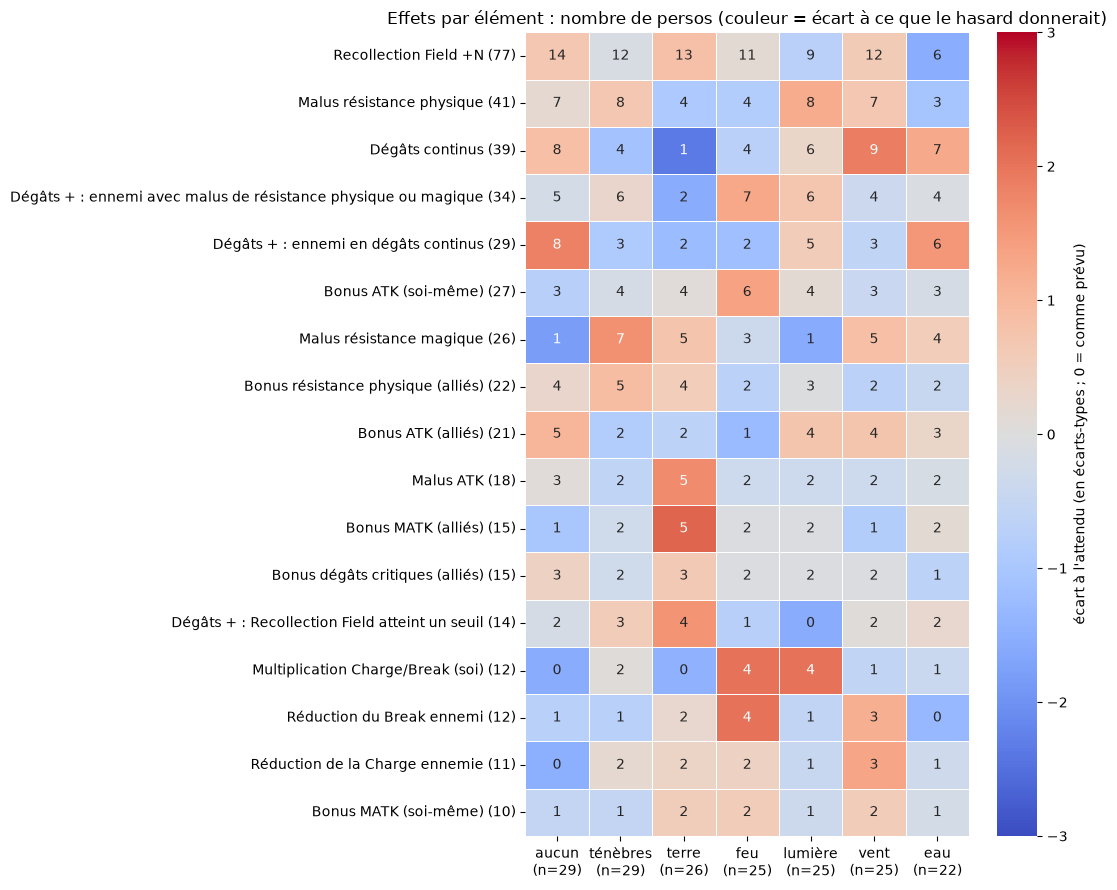

In [29]:
MIN_PERSOS = 10
effets_top = [r["effet"] for r in
              df_eff.groupBy("effet").agg(F.countDistinct("perso_id").alias("nb"))
              .filter(F.col("nb") >= MIN_PERSOS)
              .orderBy(F.desc("nb"), "effet").collect()]
n_el = df_perso.groupBy("element").count().toPandas().set_index("element")["count"].loc[ELEMENTS]
N = int(n_el.sum())

cnt = (df_eff.filter(F.col("effet").isin(effets_top)).select("perso_id", "element", "effet").distinct()
       .groupBy("effet").pivot("element", ELEMENTS).count().na.fill(0)
       .toPandas().set_index("effet").loc[effets_top, ELEMENTS])

# Écart à l'attendu, en écarts-types (loi hypergéométrique)
k = cnt.sum(axis=1)
pp = (k / N).values[:, None]
attendu = pp * n_el.values[None, :]
var = n_el.values[None, :] * pp * (1 - pp) * (N - n_el.values[None, :]) / (N - 1)
z = pd.DataFrame((cnt.values - attendu) / np.sqrt(var), index=cnt.index, columns=cnt.columns)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(z.set_axis([f"{e} ({int(k[e])})" for e in z.index])
             .set_axis([f"{c}\n(n={n_el[c]})" for c in z.columns], axis=1),
            annot=cnt.values, fmt="d", cmap="coolwarm", vmin=-3, vmax=3, center=0,
            linewidths=0.5, ax=ax,
            cbar_kws={"label": "écart à l'attendu (en écarts-types ; 0 = comme prévu)"})
ax.set_title("Effets par élément : nombre de persos (couleur = écart à ce que le hasard donnerait)")
plt.tight_layout()
plt.show()

In [30]:
print("persos « Bonus dégâts critiques (alliés) » :",
      df_eff.filter(F.col("effet") == "Bonus dégâts critiques (alliés)")
            .select("perso_id").distinct().count())
print("len(global_) :", len(global_))

# Ton perso eau, directement
(df_eff.filter(F.col("perso_id") == 130124039)
       .select("slot", "effet").distinct().orderBy("slot", "effet")
       .show(truncate=False))

persos « Bonus dégâts critiques (alliés) » : 15
len(global_) : 49
+------------+-------------------------------+
|slot        |effet                          |
+------------+-------------------------------+
|competence_1|Malus résistance physique      |
|competence_1|Recollection Field +N          |
|competence_2|Bonus ATK (alliés)             |
|competence_2|Bonus dégâts critiques (alliés)|
|competence_3|Bonus ATK (alliés)             |
|competence_3|Bonus dégâts critiques (alliés)|
+------------+-------------------------------+



In [31]:
SLOTS_COMPETENCES = ["competence_1", "competence_2", "competence_3"]
SLOTS_INCARNATION = ["incarnation"]

ELEMENTS = [r["element"] for r in
            df_perso.groupBy("element").count().orderBy(F.desc("count"), "element").collect()]

SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"

# Phrases déjà traitées ailleurs (Break, Charge, Mode enhance, Enhance, Heal) ou sans intérêt ici
EXCLUS = (r"^(Brise la Volonté|Charge la Volonté de|Entre soi-même en mode|Capacité d'un allié|Soins HP"
          r"|Attaque (tranchante|magique|perçante|de frappe)( de Volonté)?( à puissance énorme)? sur (un ennemi|tous les ennemis)$"
          r"|Temps de préparation|Rotation|\（仮\）|$)")

# ----------------------------------------------------------------------------------------------
# Règles de regroupement
# ----------------------------------------------------------------------------------------------
REGLES = [
    (r"^Résistances? physique( et magique)? -N%", "Malus résistance physique"),
    (r"^Résistance magique (sur l'ennemi )?-N%|^Résistances? physique et magique -N%"
     r"|^Résistance physique -N% et résistance magique -N%", "Malus résistance magique"),
    (r"^Résistance à l'élément [^ ]+ -N%|^La résistance à l'élément [^ ]+ diminue"
     r"|et de N% la résistance à l'élément", "Malus résistance d'élément"),
    (r"^De plus, DEF et MDEF -N% si l'ennemi", "Malus DEF et MDEF (ennemi d'un élément)"),
    (r"^ATK -N%", "Malus ATK"),
    (r"^MATK -N%", "Malus MATK"),
    (r"^MP -N% pour l'élément", "Malus MP selon l'élément"),
    (r"^Élément [^ ]+ -N% sur l'ennemi", "Malus d'élément sur l'ennemi"),
    (r"^Réduit de N% le Break de Volonté de l'ennemi", "Réduction du Break ennemi"),
    (r"^Réduit de N% le Break de la compétence ennemie", "Réduction du Break de la compétence ennemie"),
    (r"^Réduit (de N% )?la Charge de Volonté (ennemie|de l'ennemi)|^Charge de Volonté de l'ennemi -N%", "Réduction de la Charge ennemie"),
    (r"^Inflige des dégâts continus", "Dégâts continus"),
    (r"^Provoque l'ennemi", "Provocation"),
    (r"^Inflige une contre-attaque", "Contre-attaque"),
    (r"^(Guérit|Soigne|Guérison)", "Guérison / soin de statut"),
    (r"^Restauration de MP", "Restauration de MP (alliés)"),
    (r"^Absorption des HP", "Absorption de HP"),
    (r"^Multiplie (sa|le|la) |^Capacité à charger", "Multiplication Charge/Break (soi)"),
    (r"^Attaque .*N% de dégâts de HP maximum", "Attaque avec coût en HP"),
    (r"^Et attaque ", "Attaque supplémentaire"),
    (r"^En contrepartie|^Résistance [^ ]+ sur soi-même -N%", "Malus en contrepartie"),
]

BONUS = [
    (r"(?<![A-Za-z])ATK", "Bonus ATK"),                  # pas de lettre devant : MATK est à part
    (r"MATK", "Bonus MATK"),
    (r"[Rr]ésistances? physique", "Bonus résistance physique"),
    (r"[Rr]ésistances? (physique et )?magique", "Bonus résistance magique"),
    (r"[Rr]ésistance (d'|à l')élément", "Bonus résistance d'élément"),
    (r"[Dd]égâts critiques", "Bonus dégâts critiques"),
    (r"Taux de coup critique", "Bonus taux de critique"),
    (r"Taux d'esquive", "Bonus esquive"),
]

# ----------------------------------------------------------------------------------------------
# Construction de la table des effets (une ligne par perso, compétence et effet)
# ----------------------------------------------------------------------------------------------

def normaliser(col):
    c = F.regexp_replace(col, "’", "'")                                      # apostrophe typographique
    c = F.regexp_replace(c, r"tour\(s\)", "tours")
    c = F.regexp_replace(c, r"\s*\([^()]*(tours|maximum)[^()]*\)", "")        # durées et « maximum »
    c = F.regexp_replace(c, r"\s*\((faible|moyenne|forte|énorme)\)", "")      # intensités
    c = F.regexp_replace(c, r"\d+(,\d+)?", "N")                               # nombres
    c = F.regexp_replace(c, r"\s+", " ")
    c = F.regexp_replace(c, r"[\s.,;]+$", "")
    return F.trim(c)

def construire_effets(slots):
    def phrase_du_slot(slot):
        c = F.col(f"competences.{slot}")
        return df_perso.select(
            F.col("id").alias("perso_id"), "element", F.lit(slot).alias("slot"),
            F.element_at(c["niveau"], -1)["desciption"].alias('description')
        )
    df_phr = (
        reduce(lambda a, b:a.unionByName(b), [phrases_du_slot(s) for s in slots])
        .select("perso_id", "element", "slot", F.explode(F.split(F.trim("description"), SPLIT)).alias("phrase"))
        .withColumn("p", normaliser(F.col("phrase")))
        .filter(~F.col("p").rlike(EXCLUS))
    )

    p = F.col("p")
    vide = F.array().cast("array<string>")

    def correspondancec(regles):
        return F.filter(F.array(*[F.when(p.rlike(r), F.lit(n)) for r, n in regles]), lambda x: x.isNotNull())

    # a) Recollection Field : la valeur (+1, +2, +3) se lit dans le texte d'origine (colonne « phrase »)
    est_rf = p.rlike(r"^Recollection Field")
    rf_valeur = F.regexp_extract(F.col("phrase"), r"^Recollection Field(?: spécial)? \([^)]*\)\s*\+(\d+)", 1)
    etiq_rf = (
        F.when(p.rlike(r"^Recollection Field spécial"),
               F.array(F.concat(F.lit("Recollection Field spécial +"), rf_valeur)))
         .when(est_rf, F.array(F.concat(F.lit("Recollection Field +"), rf_valeur)))
         .otherwise(vide)
    )

    # b) « Augmentation de … » : effet augmenté + condition
    est_boost = ~est_rf & p.rlike(
        r"[Aa]ugmentation (de N% )?(des dégâts(?! critiques)|de la Charge de Volonté|de la capacité à briser|du Break de Volonté)"
        r"|^Augmente les dégâts(?! critiques)|^Lance sur tous les alliés un bonus augmentant les dégâts")
    effet_boost = (
        F.when(p.rlike(r"[Aa]ugmentation (de N% )?des dégâts(?! critiques)|^Augmente les dégâts(?! critiques)|bonus augmentant les dégâts"), "Dégâts")
         .when(p.rlike(r"[Aa]ugmentation de la Charge"), "Charge de Volonté")
         .otherwise("Break de Volonté")
    )
    condition = (
        F.when(p.contains("subissant des dégâts continus"), "ennemi en dégâts continus")
         .when(p.contains("subissant un malus de résistance"),
               F.concat(F.lit("ennemi avec malus de résistance "),
                        F.regexp_extract(p, r"malus de résistance\s*(.*)$", 1)))
         .when(p.contains("Recollection Field"), "Recollection Field atteint un seuil")
         .when(p.contains("lien de compétences"), "lien de compétences")
         .when(p.contains("nombre de cibles"), "nombre de cibles")
         .when(p.rlike(r"Volonté de l'ennemi (dépasse|est de N% ou plus)"), "Volonté ennemie au-dessus d'un seuil")
         .when(p.rlike(r"(quand|lorsque) le bonus"), "bonus d'ATK ou de critique atteint un seuil")
         .otherwise("autre condition")
    )
    etiq_boost = F.when(est_boost, F.array(F.concat(effet_boost, F.lit(" + : "), condition))).otherwise(vide)

    # c) Bonus : on cherche chaque stat citée dans la phrase, la cible est ajoutée une seule fois
    cible = (F.when(p.contains("soi-même"), " (soi-même)")
              .when(p.rlike("alliés?"), " (alliés)")
              .otherwise(" (cible non précisée)"))
    est_bonus = ~est_boost & ~est_rf & p.rlike(
        r"\+N%|en augmentant de N%|en augmentant l'(ATK|MATK) de N%"
        r"|^Augmentation de N% des dégâts critiques|^Augmente les dégâts critiques de N%")
    etiq_bonus = F.when(est_bonus,
                        F.transform(correspondances(BONUS), lambda n: F.concat(n, cible))).otherwise(vide)

    # d) Assemblage : une phrase peut avoir plusieurs effets ; sans aucun effet reconnu -> « Autre »
    toutes = F.concat(etiq_rf, etiq_boost, correspondances(REGLES), etiq_bonus)
    df_eff = (df_phr
              .withColumn("effets", F.when(F.size(toutes) == 0, F.array(F.lit("Autre"))).otherwise(toutes))
              .withColumn("effet", F.explode("effets"))
              .drop("effets"))

    autres = df_eff.filter(F.col("effet") == "Autre").select("p").distinct().collect()
    print(f"{slots} : {df_eff.select('effet').distinct().count()} effets distincts | "
          f"phrases non classées (« Autre ») : {len(autres)}")
    for r in autres:
        print("   non classée :", r["p"])
    return df_eff


# ----------------------------------------------------------------------------------------------
# Graphiques
# ----------------------------------------------------------------------------------------------
COUL = {"Recollection Field": "#e0a800", "Augmentation conditionnelle": "#3b7dd8",
        "Bonus (buff)": "#4caf50", "Malus sur l'ennemi": "#d9534f",
        "Autres mécaniques": "#9e9e9e", "Non classé": "#333333"}

def categorie(e):
    if e.startswith("Recollection Field"): return "Recollection Field"
    if " + : " in e: return "Augmentation conditionnelle"
    if e.startswith("Bonus"): return "Bonus (buff)"
    if e == "Autre": return "Non classé"
    if e.startswith(("Malus", "Réduction")) and e != "Malus en contrepartie": return "Malus sur l'ennemi"
    return "Autres mécaniques"

def graphique_global(df_eff, titre):
    """Nombre de persos par effet : TOUS les effets sont affichés."""
    g = (df_eff.groupBy("effet").agg(F.countDistinct("perso_id").alias("nb_persos"))
         .orderBy(F.desc("nb_persos"), "effet").toPandas())
    g = g.iloc[::-1]                                              # le plus grand en haut
    fig, ax = plt.subplots(figsize=(11, max(5, 0.30 * len(g) + 1.5)))
    ax.barh(g["effet"], g["nb_persos"], color=g["effet"].map(lambda e: COUL[categorie(e)]))
    for y, v in enumerate(g["nb_persos"]):
        ax.text(v + g["nb_persos"].max() * 0.008, y, int(v), va="center", fontsize=8)
    for lbl in ax.get_yticklabels():                              # les Recollection Field ressortent
        if lbl.get_text().startswith("Recollection Field"):
            lbl.set_fontweight("bold")
    presentes = [c for c in COUL if c in set(g["effet"].map(categorie))]
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=COUL[c]) for c in presentes], presentes,
              title="Type", loc="lower right")
    ax.set_title(f"{titre}\n(nombre de persos concernés, {len(g)} effets)")
    ax.set_xlabel("Nombre de personnages")
    ax.set_xlim(0, g["nb_persos"].max() * 1.08)
    plt.tight_layout()
    plt.show()
    return g.iloc[::-1].reset_index(drop=True)

def graphique_par_element(df_eff, titre, seuil_couleur=10):
    """Persos par effet et par élément : TOUS les effets sont affichés.
    La couleur (écart à l'attendu) n'est calculée que pour les effets d'au moins `seuil_couleur` persos."""
    n_el = df_perso.groupBy("element").count().toPandas().set_index("element")["count"].loc[ELEMENTS]
    N = int(n_el.sum())
    cnt = (df_eff.select("perso_id", "element", "effet").distinct()
           .groupBy("effet").pivot("element", ELEMENTS).count().na.fill(0)
           .toPandas().set_index("effet")[ELEMENTS])
    cnt["_k"] = cnt.sum(axis=1)
    cnt = cnt.loc[sorted(cnt.index, key=lambda e: (-cnt.loc[e, "_k"], e))]    # plus fréquents d'abord
    k = cnt.pop("_k")

    pp = (k / N).values[:, None]
    attendu = pp * n_el.values[None, :]
    var = n_el.values[None, :] * pp * (1 - pp) * (N - n_el.values[None, :]) / (N - 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        z = pd.DataFrame((cnt.values - attendu) / np.sqrt(var), index=cnt.index, columns=cnt.columns)
    z = z.fillna(0)
    z.loc[k < seuil_couleur] = 0                                  # trop peu de persos : couleur neutre

    labels_l = [f"{e} ({int(k[e])})" for e in z.index]
    labels_c = [f"{c}\n(n={n_el[c]})" for c in z.columns]
    fig, ax = plt.subplots(figsize=(11, max(6, 0.30 * len(z) + 2.5)))
    sns.heatmap(z.set_axis(labels_l).set_axis(labels_c, axis=1),
                annot=cnt.values, fmt="d", annot_kws={"fontsize": 8},
                cmap="coolwarm", vmin=-3, vmax=3, center=0, linewidths=0.5, ax=ax,
                cbar_kws={"label": "écart à l'attendu (en écarts-types ; 0 = comme prévu)"})
    ax.tick_params(axis="y", labelsize=8)
    for i, (lbl, e) in enumerate(zip(ax.get_yticklabels(), z.index)):     # cadre doré autour des Recollection Field
        if e.startswith("Recollection Field"):
            lbl.set_fontweight("bold")
            ax.add_patch(plt.Rectangle((0, i), len(z.columns), 1, fill=False, edgecolor="#e0a800", lw=2.5, clip_on=False))
    ax.set_title(f"{titre}\n(nombre de persos ; couleur = écart à ce que le hasard donnerait ;"
                 f" neutre si moins de {seuil_couleur} persos)")
    plt.tight_layout()
    plt.show()
    return cnt

['competence_1', 'competence_2', 'competence_3'] : 49 effets distincts | phrases non classées (« Autre ») : 0


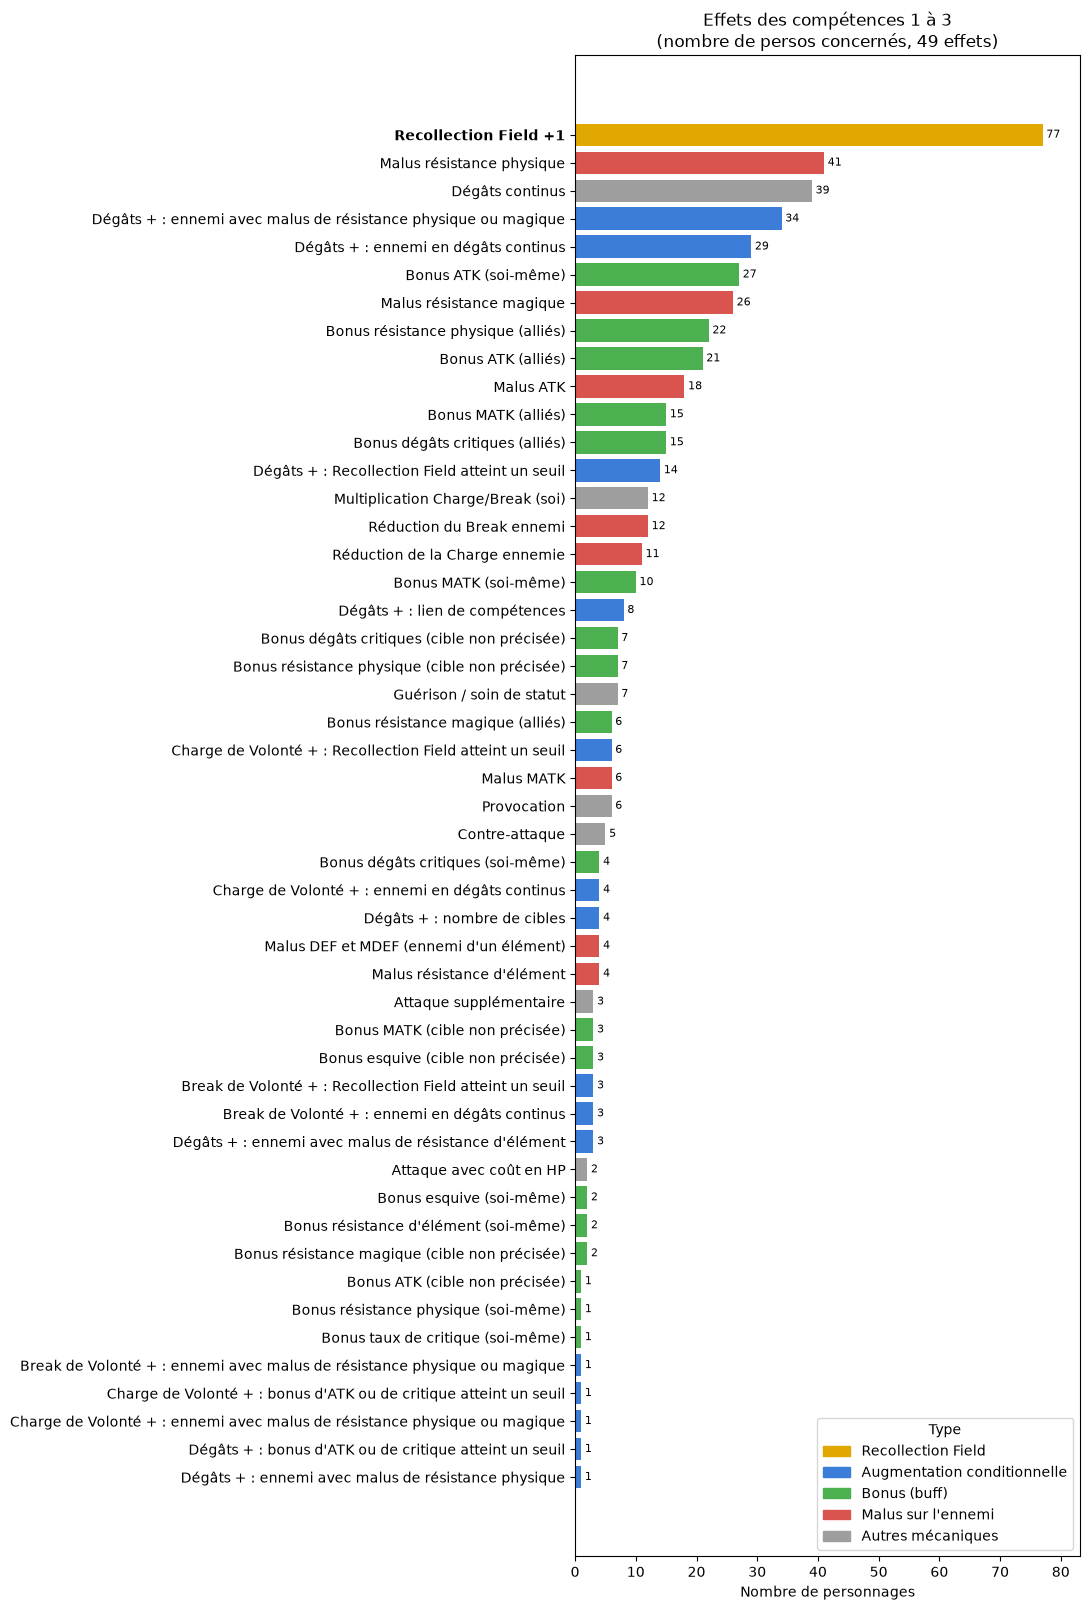

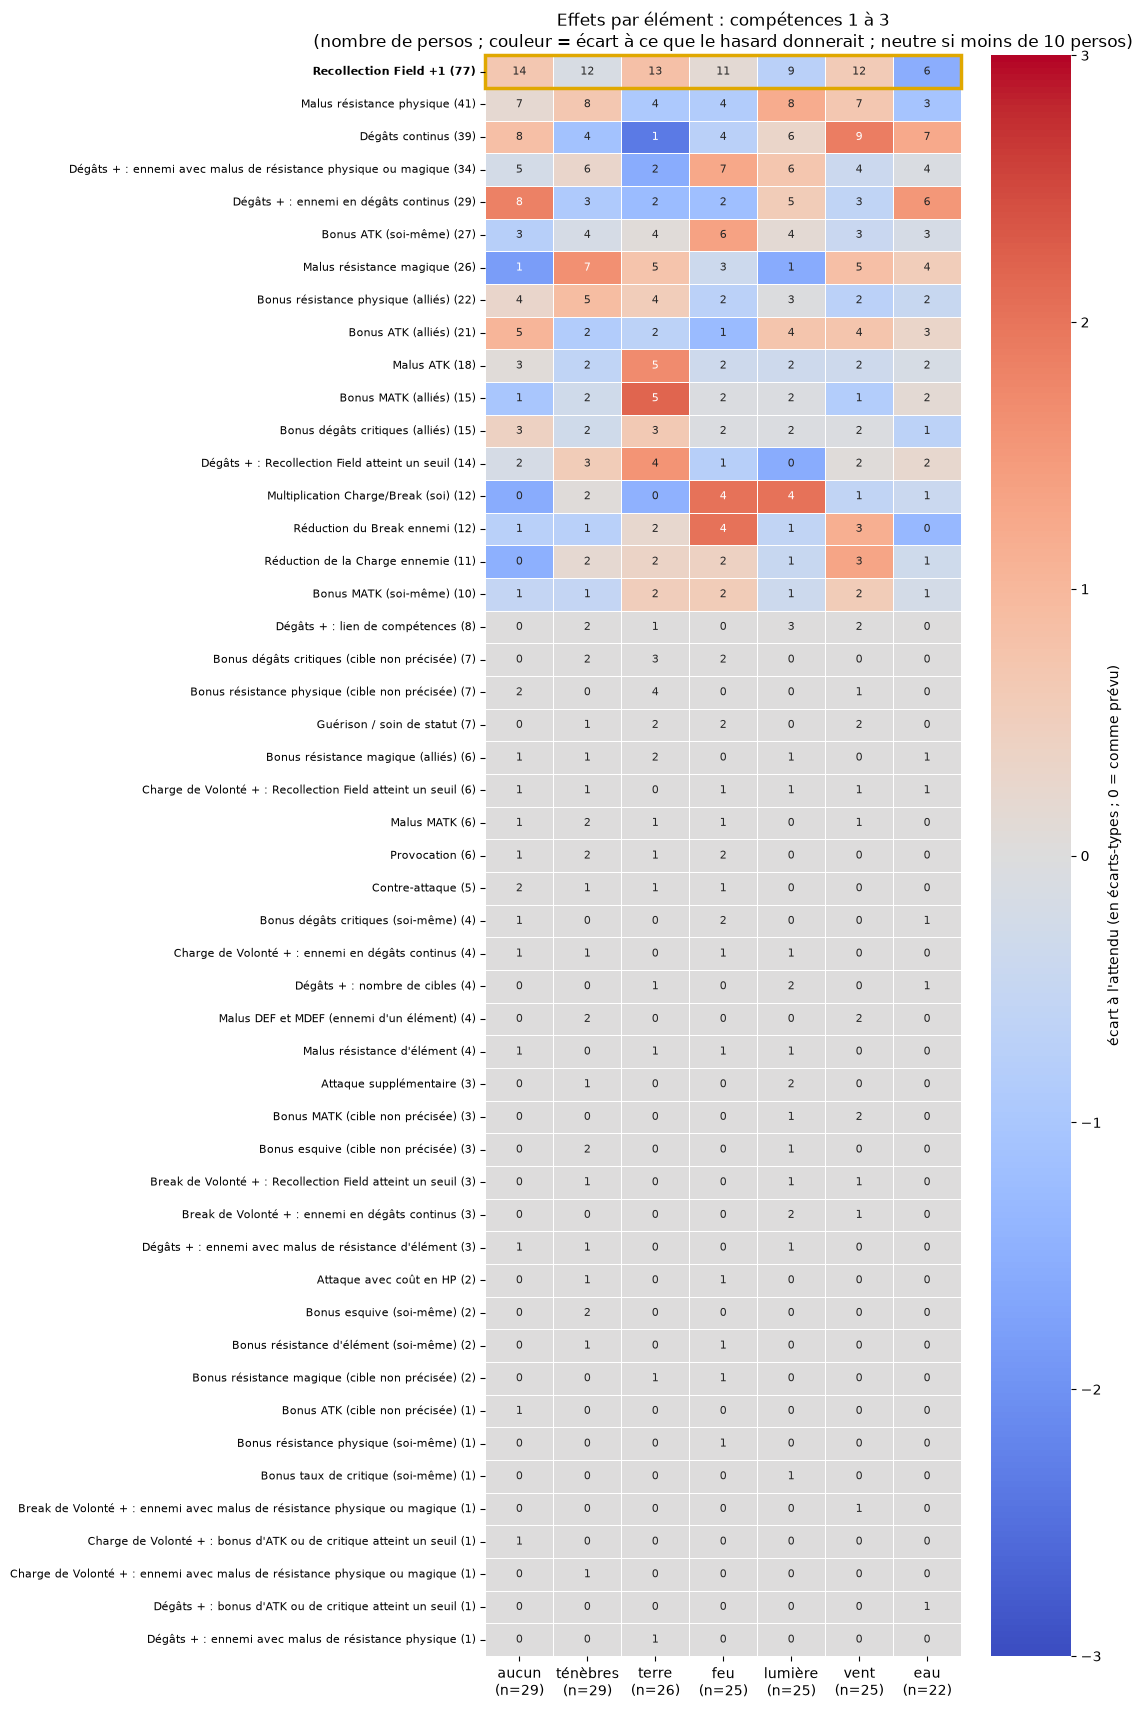

In [32]:
df_eff_sk = construire_effets(SLOTS_COMPETENCES)
table_global_sk = graphique_global(df_eff_sk, "Effets des compétences 1 à 3")
table_element_sk = graphique_par_element(df_eff_sk, "Effets par élément : compétences 1 à 3")

['incarnation'] : 26 effets distincts | phrases non classées (« Autre ») : 0


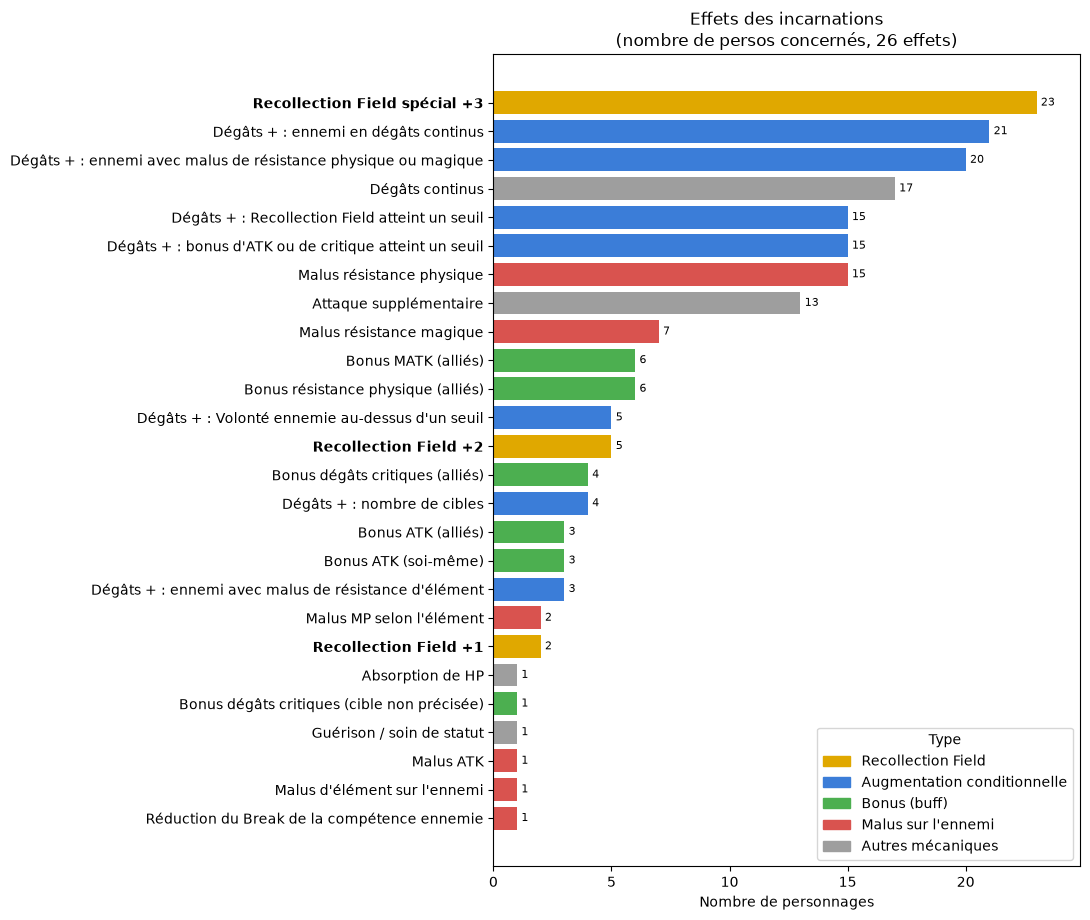

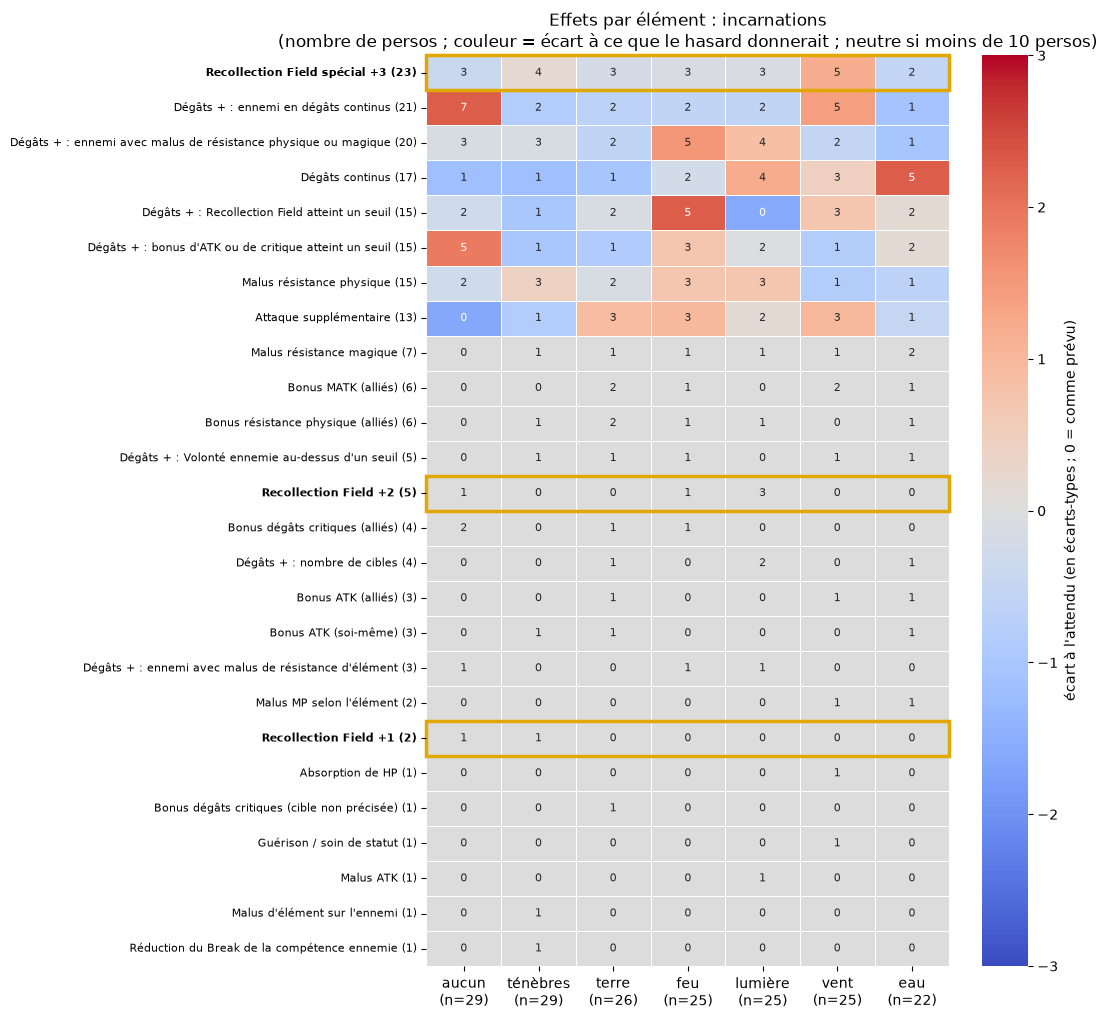

In [33]:
df_eff_inc = construire_effets(SLOTS_INCARNATION)
table_global_inc = graphique_global(df_eff_inc, "Effets des incarnations")
table_element_inc = graphique_par_element(df_eff_inc, "Effets par élément : incarnations")

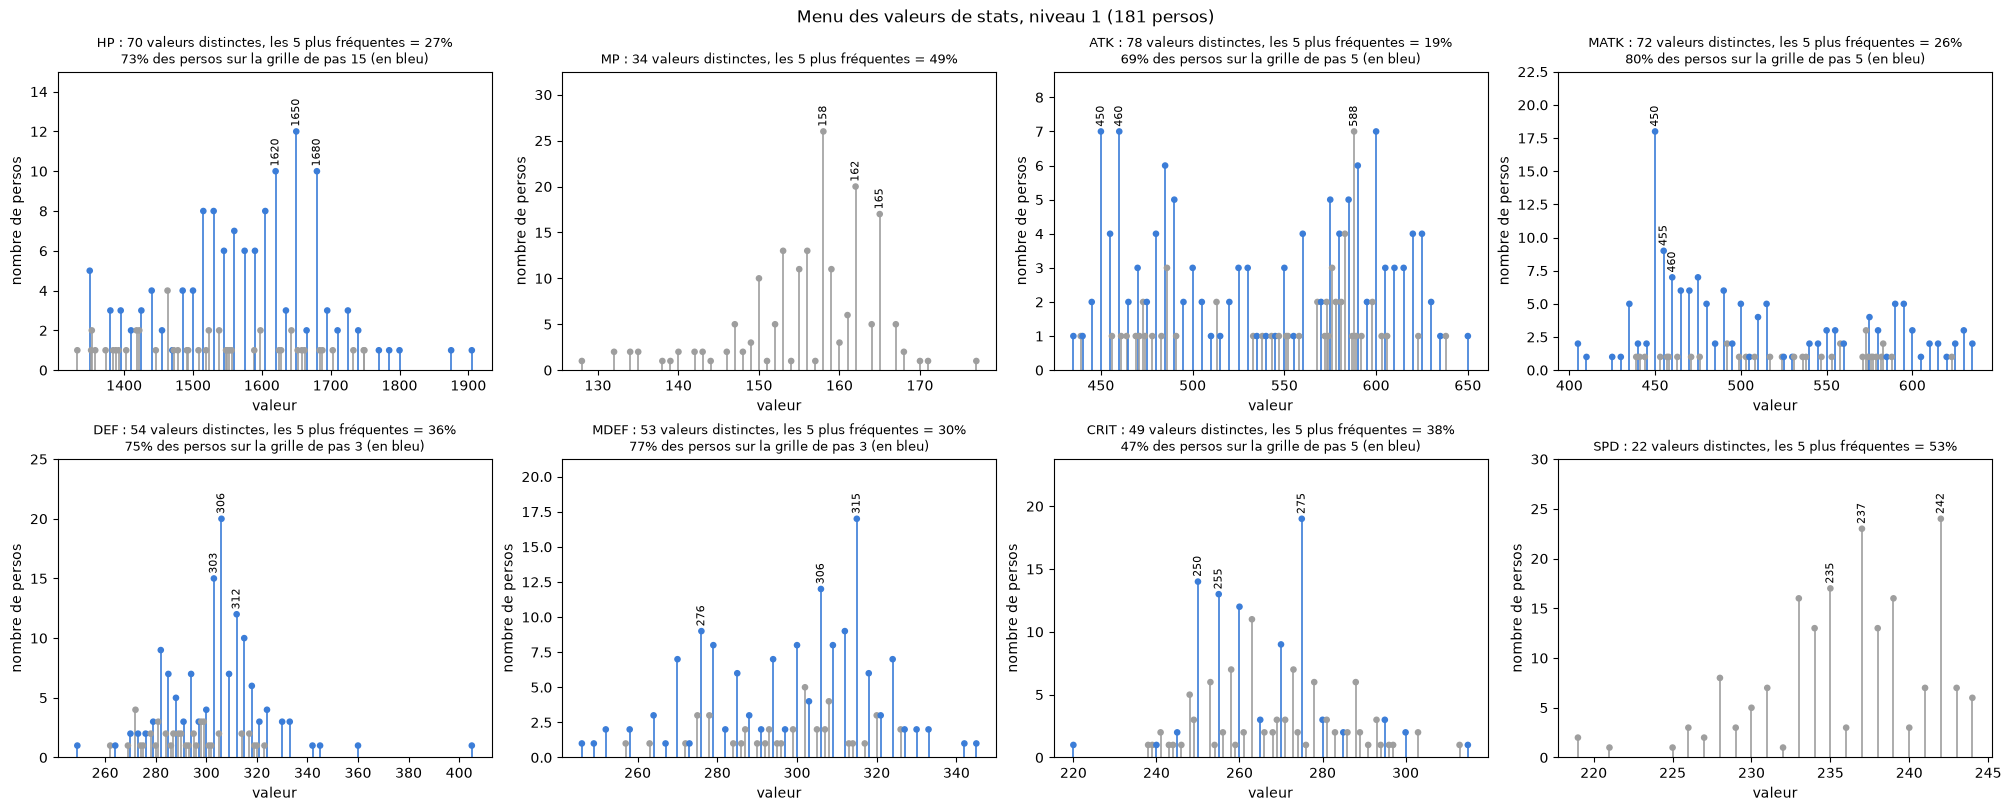

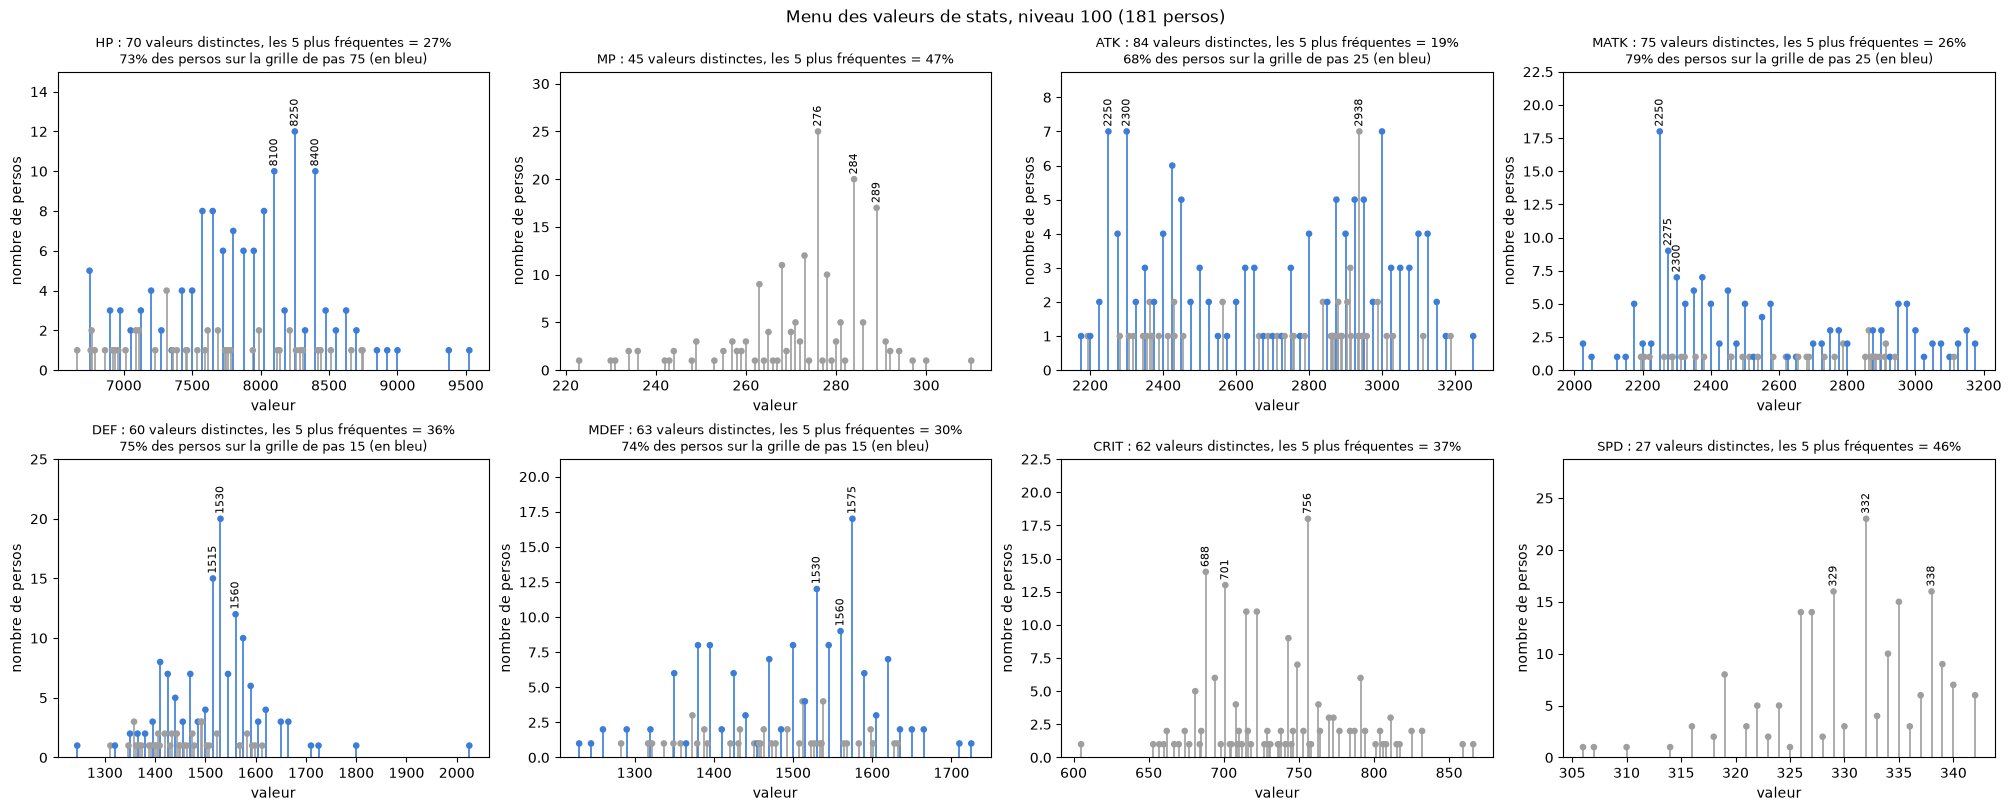

,HP,MP,ATK,MATK,DEF,MDEF,CRIT,SPD
0,7500,276,2700,2550,1455,1395,701,319
1,7875,278,2575,2500,1365,1380,681,318
2,7650,269,2650,2450,1485,1395,718,321
3,7725,286,2563,2250,1358,1373,722,330
4,6750,242,2838,2313,1403,1598,811,327
...,...,...,...,...,...,...,...,...
176,8250,284,3125,2250,1590,1590,756,332
177,8250,236,2900,2050,1650,1230,756,337
178,8100,257,2938,2025,1665,1260,731,337
179,8250,273,3050,2250,1530,1530,688,332


In [7]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def graphique_menu_stats(niveau=1):
    """Pour chaque stat : combien de persos ont EXACTEMENT chaque valeur.
    niveau=1 : les valeurs « sources » (celles du niveau 100 en découlent) ; niveau=100 : valeurs du niveau 100.
    Les points bleus sont les valeurs qui tombent sur la grille repérée pour cette stat."""
    if niveau == 1:
        pas = {"HP": 15, "DEF": 3, "MDEF": 3, "ATK": 5, "MATK": 5, "CRIT": 5}
    elif niveau == 100:
        pas = {"HP": 75, "DEF": 15, "MDEF": 15, "ATK": 25, "MATK": 25}      # le niveau 1 multiplié par 5
    else:
        pas = {}

    pdf = df_perso.select(*[F.col(f"stats.lvl_{niveau}.{s}").alias(s) for s in STATS]).toPandas()

    fig, axes = plt.subplots(2, 4, figsize=(20, 8), layout="constrained")
    for ax, s in zip(axes.ravel(), STATS):
        c = pdf[s].value_counts().sort_index()                       # valeur -> nombre de persos
        sur_grille = (c.index % pas[s] == 0) if s in pas else np.zeros(len(c), dtype=bool)
        couleurs = np.where(sur_grille, "#3b7dd8", "#9e9e9e")
        ax.vlines(c.index, 0, c.values, color=couleurs, linewidth=1.2)
        ax.scatter(c.index, c.values, c=couleurs, s=14, zorder=3)
        for valeur, n in c.nlargest(3).items():                       # les 3 valeurs les plus partagées
            ax.text(valeur, n + c.max() * 0.02, str(valeur), ha="center", va="bottom", rotation=90, fontsize=8)
        top5 = c.nlargest(5).sum() / len(pdf)
        titre = f"{s} : {len(c)} valeurs distinctes, les 5 plus fréquentes = {top5:.0%}"
        if s in pas:
            titre += f"\n{(pdf[s] % pas[s] == 0).mean():.0%} des persos sur la grille de pas {pas[s]} (en bleu)"
        ax.set_title(titre, fontsize=9)
        ax.set_xlabel("valeur"); ax.set_ylabel("nombre de persos")
        ax.set_ylim(0, c.max() * 1.25)
    fig.suptitle(f"Menu des valeurs de stats, niveau {niveau} ({len(pdf)} persos)", fontsize=12)
    plt.show()
    return pdf


pdf_stats = graphique_menu_stats(1)      # niveau 1 : les valeurs de départ
graphique_menu_stats(100)                # même structure, à l'échelle du niveau 100

In [ ]:
pdf_stats = graphique_menu_stats(1)
(pdf_stats["HP"] % 15 == 0).mean()      # part des persos dont le HP est un multiple de 15